# Model selection for live active sampling

Picks about five historical → local pairs for live runs, starting from the evaluation ZIP. Compared with the ZIP alone, it adds a 30-seed random baseline, historical-model seeds 0–4, and replays on the current data.

Results are cached in `model-selection-cache/`; `RECOMPUTE = True` reruns everything (about 1–1.5 h). All fits use one BLAS thread. `small-mlp` still differs between runs with the same `random_state` (its optimiser amplifies tiny numerical differences), so its cached results are one sample, not exact values.

In [1]:
from pathlib import Path
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

import model_selection as ms
from ml.models import MODEL_TYPES

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.precision", 2)

In [2]:
RESULTS = Path("evaluation-results-3seeds-25steps.zip")
EVAL_REV = "ce0ebc49^"   # data the ZIP was produced from
CURRENT_REV = "HEAD"     # data live sampling trains on
CACHE = Path("model-selection-cache")
RECOMPUTE = False
JOBS = 8                 # ~1.5 GB RAM per worker
RANDOM_SEEDS = 30
HIST_SEEDS = 5
LOCALS = ["bayes-pairs", "gaussian-process"]
HARD = ["8845HS", "3900X", "i5-1038NG7"]

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e6e5e0", "#ffffff", "#c3c2b7"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 200, "font.size": 14,
                     "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Arimo", "Liberation Sans", "DejaVu Sans"], "axes.titlesize": 16,
                     "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 14})
TITLE_STYLE = dict(loc="left", fontsize=20, fontweight="bold", pad=12)
SLIDE = (12, 6.4)   # figure size for the slide figures (2, 5, 4, 1b)

## 1. Inputs

- **ZIP data**: `llama/results` at `EVAL_REV`, which matches the ZIP's pools.
- **current data (HEAD)**: the same as the ZIP data, plus CPU-only 5800X builds.
- Both are replays of builds that were already measured; nothing is measured again.
- Hardware and no-hardware variants of a local model are identical, so they are merged.

In [3]:
sessions = ms.load_eval(RESULTS)
eval_commit, eval_data, eval_path = ms.snapshot(EVAL_REV, CACHE)
current_commit, current_data, current_path = ms.snapshot(CURRENT_REV, CACHE)
eval_table, current_table = ms.load_pools(eval_path), ms.load_pools(current_path)
SNAPSHOTS = {"eval": (eval_data, eval_table), "current": (current_data, current_table)}  # key: tree hash of llama/results
COMMITS = {"eval": eval_commit, "current": current_commit}
NAMES = {"eval": "ZIP data", "current": "current data (HEAD)"}

def pool_summary(table):
    return table.groupby(table.platform.map(ms.SHORT)).performance.agg(builds="size", best="max")

pools = pd.concat({f"{label} ({COMMITS[label]})": pool_summary(table) for label, (data, table) in SNAPSHOTS.items()}, axis=1)
pools[("ZIP", "best")] = ms.zip_pool_best(RESULTS)
# display(pools.round(1))
assert np.allclose(pools[(f"eval ({eval_commit})", "best")], pools[("ZIP", "best")]), "EVAL_REV does not match the ZIP"

warm, cold = sessions[sessions.pretrained != "none"], sessions[sessions.pretrained == "none"]
# display(pd.DataFrame({
#     "policies": [warm.groupby(["pretrained", "model"]).ngroups, cold.model.nunique()],
#     "seeds": [warm.seed.nunique(), cold.seed.nunique()],
#     "platforms": [warm.platform.nunique(), cold.platform.nunique()],
#     "sessions": [len(warm), len(cold)],
# }, index=["warm: historical → local", "cold (incl. random)"]))

spread = sessions.groupby(["platform", "pretrained", "local", "seed"])[ms.BEST].agg(lambda x: x.max() - x.min())
print(f"max difference within a local-model family: {spread.to_numpy().max():.2g} pp")
sessions = sessions.drop_duplicates(["platform", "pretrained", "local", "seed"])

max difference within a local-model family: 0 pp


## 2. Metrics

- **Best build found so far** (% of pool best) after each step → figures 1 / 1b.
- **AUC**: mean of best-so-far over steps 3–25; rewards early finds → figure 4 (current data).
- **Δ vs random**: AUC minus a 30-seed random baseline on the same platform; this is the ranking criterion → figure 6.
- **Final recommended build** (% of pool best): used to choose the local model → figure 5.

Not used: final prediction accuracy (mostly already measured builds), convergence round, timing, combined score.

In [4]:
checks = ms.quality_checks(RESULTS)
# display(checks["already_measured"].round(2))
# display(checks["seconds_per_round"].round(2))

random = {label: ms.with_auc(ms.cached(CACHE / f"random-{data}-{RANDOM_SEEDS}.csv",
                                       lambda table=table: ms.random_baseline(table, RANDOM_SEEDS, JOBS), RECOMPUTE))
          for label, (data, table) in SNAPSHOTS.items()}
METRICS = ["auc", "best@5", "best@10", "best@25"]
random_mean = {label: frame.groupby("platform")[METRICS].mean() for label, frame in random.items()}
zip_random = sessions[sessions.model == "random"].groupby("platform")[METRICS].mean()
baseline = pd.concat({"eval, 30 seeds": random_mean["eval"], "current, 30 seeds": random_mean["current"],
                      "ZIP, 3 seeds": zip_random}, axis=1)
baseline.loc["mean"] = baseline.mean()
# display(baseline.round(1))

## 3. All evaluated pairs (ZIP)

In [5]:
per_platform = sessions.groupby(["platform", "pretrained", "local"])[METRICS + ["rec@25"]].mean()
for metric in METRICS:
    per_platform[f"Δ {metric}"] = per_platform[metric] - random_mean["eval"][metric].reindex(
        per_platform.index.get_level_values("platform")).to_numpy()
ranking = per_platform.groupby(["pretrained", "local"]).mean().sort_values("auc", ascending=False)
# display(ranking.head(15))

cold_vs_random = ranking.loc["none"].drop("random")
print(f"cold pairs above random: {(cold_vs_random['Δ auc'] > 0).sum()} of {len(cold_vs_random)}")
w = per_platform.loc[per_platform.index.get_level_values("pretrained") != "none", "auc"].reset_index()
w["r"] = w.auc - w.groupby("platform").auc.transform("mean")
for factor in ["pretrained", "local"]:
    share = w.groupby(["platform", factor]).r.transform("mean").var() / w.r.var()
    print(f"within-platform AUC variance explained by {factor}: {share:.0%}")

cold pairs above random: 0 of 11
within-platform AUC variance explained by pretrained: 83%
within-platform AUC variance explained by local: 1%


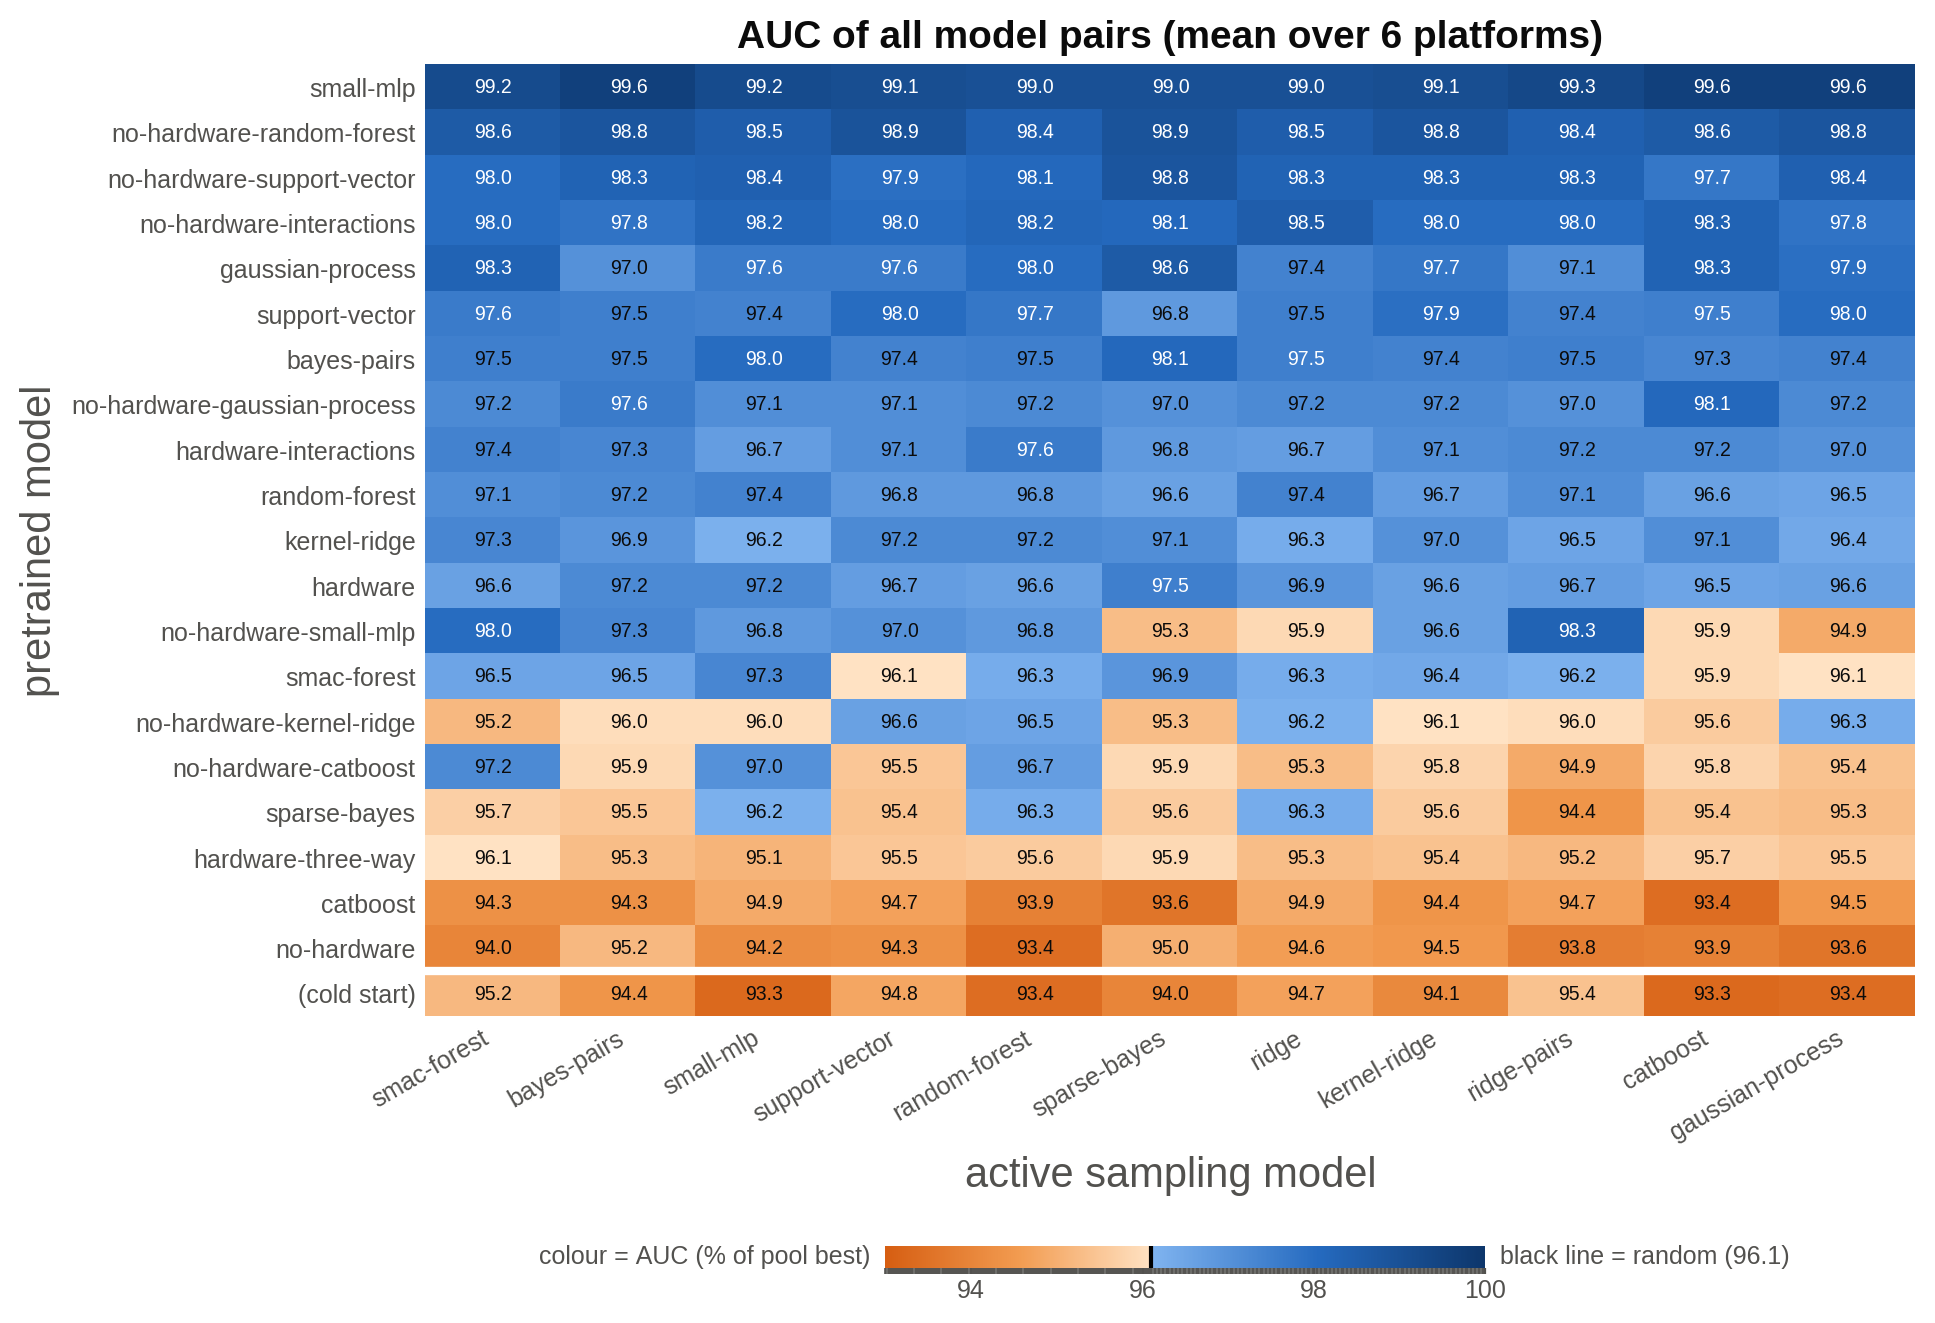

In [6]:
# Figure 2: historical × local heatmap
grid = ranking.auc.drop("none").unstack()
grid.loc["(cold start)"] = ranking.auc.loc["none"].reindex(grid.columns)
grid = grid.loc[grid.drop("(cold start)").mean(axis=1).sort_values(ascending=False).index.tolist() + ["(cold start)"]]
grid = grid[grid.mean().sort_values(ascending=False).index]
from matplotlib.colors import BoundaryNorm, ListedColormap

# Compare at the precision shown in the cells and the legend.
random_auc = round(random_mean["eval"].auc.mean(), 1)
auc_min, auc_max = 93, 100
# BoundaryNorm assigns the boundary itself to the next interval.
# Start blue at the first float above the baseline so equality stays orange.
blue_start = np.nextafter(random_auc, np.inf)
shades = 256
orange = LinearSegmentedColormap.from_list("orange", ["#d65e12", "#f29b50", "#ffe2c3"])
blue = LinearSegmentedColormap.from_list("blue", ["#80b4f0", "#256abf", "#0d366b"])
samples = np.linspace(0, 1, shades)
auc_colors = ListedColormap(np.vstack([orange(samples), blue(samples)]))
boundaries = np.concatenate([
    np.linspace(auc_min, blue_start, shades, endpoint=False),
    np.linspace(blue_start, auc_max, shades + 1),
])
auc_norm = BoundaryNorm(boundaries, auc_colors.N, clip=True)
fig, ax = plt.subplots(figsize=(10, 6.8))
fig.subplots_adjust(left=0.24, right=0.985, top=0.94, bottom=0.24)
image = ax.imshow(grid.round(1).to_numpy(), cmap=auc_colors, norm=auc_norm, aspect="auto",
                  interpolation="nearest")
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=9)
ax.tick_params(axis="both", length=0)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        value = grid.iat[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7, color=INK if value < 97.5 else "white")
ax.axhline(grid.shape[0] - 1.5, color=SURFACE, lw=3)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set(xlabel="active sampling model", ylabel="pretrained model")
platform_count = per_platform.index.get_level_values("platform").nunique()
ax.set_title(f"AUC of all model pairs (mean over {platform_count} platforms)", fontsize=14, weight="bold")

# Place the color scale below the x-axis labels, with captions on both sides.
bar_ax = fig.add_axes([0.47, 0.055, 0.30, 0.016])
bar = fig.colorbar(image, cax=bar_ax, orientation="horizontal", spacing="proportional", ticks=[94, 96, 98, 100])
bar.outline.set_visible(False)
bar.ax.tick_params(labelsize=9, length=2, pad=2)
bar.ax.axvline(random_auc, color="black", lw=1.5)
bar.ax.text(-0.025, 0.5, "colour = AUC (% of pool best)", transform=bar.ax.transAxes,
            ha="right", va="center", fontsize=9, color=INK2)
bar.ax.text(1.025, 0.5, f"black line = random ({random_auc:.1f})", transform=bar.ax.transAxes,
            ha="left", va="center", fontsize=9, color=INK2)
plt.show()

In [7]:
warm_platform = per_platform.drop("none", level="pretrained").reset_index()
for metric in ["auc", "rec@25"]:
    warm_platform[f"rank {metric}"] = warm_platform.groupby(["platform", "pretrained"])[metric].rank(ascending=False)
# display(warm_platform.groupby("local")[["rank auc", "rank rec@25", "auc", "rec@25"]].mean().sort_values("rank rec@25"))

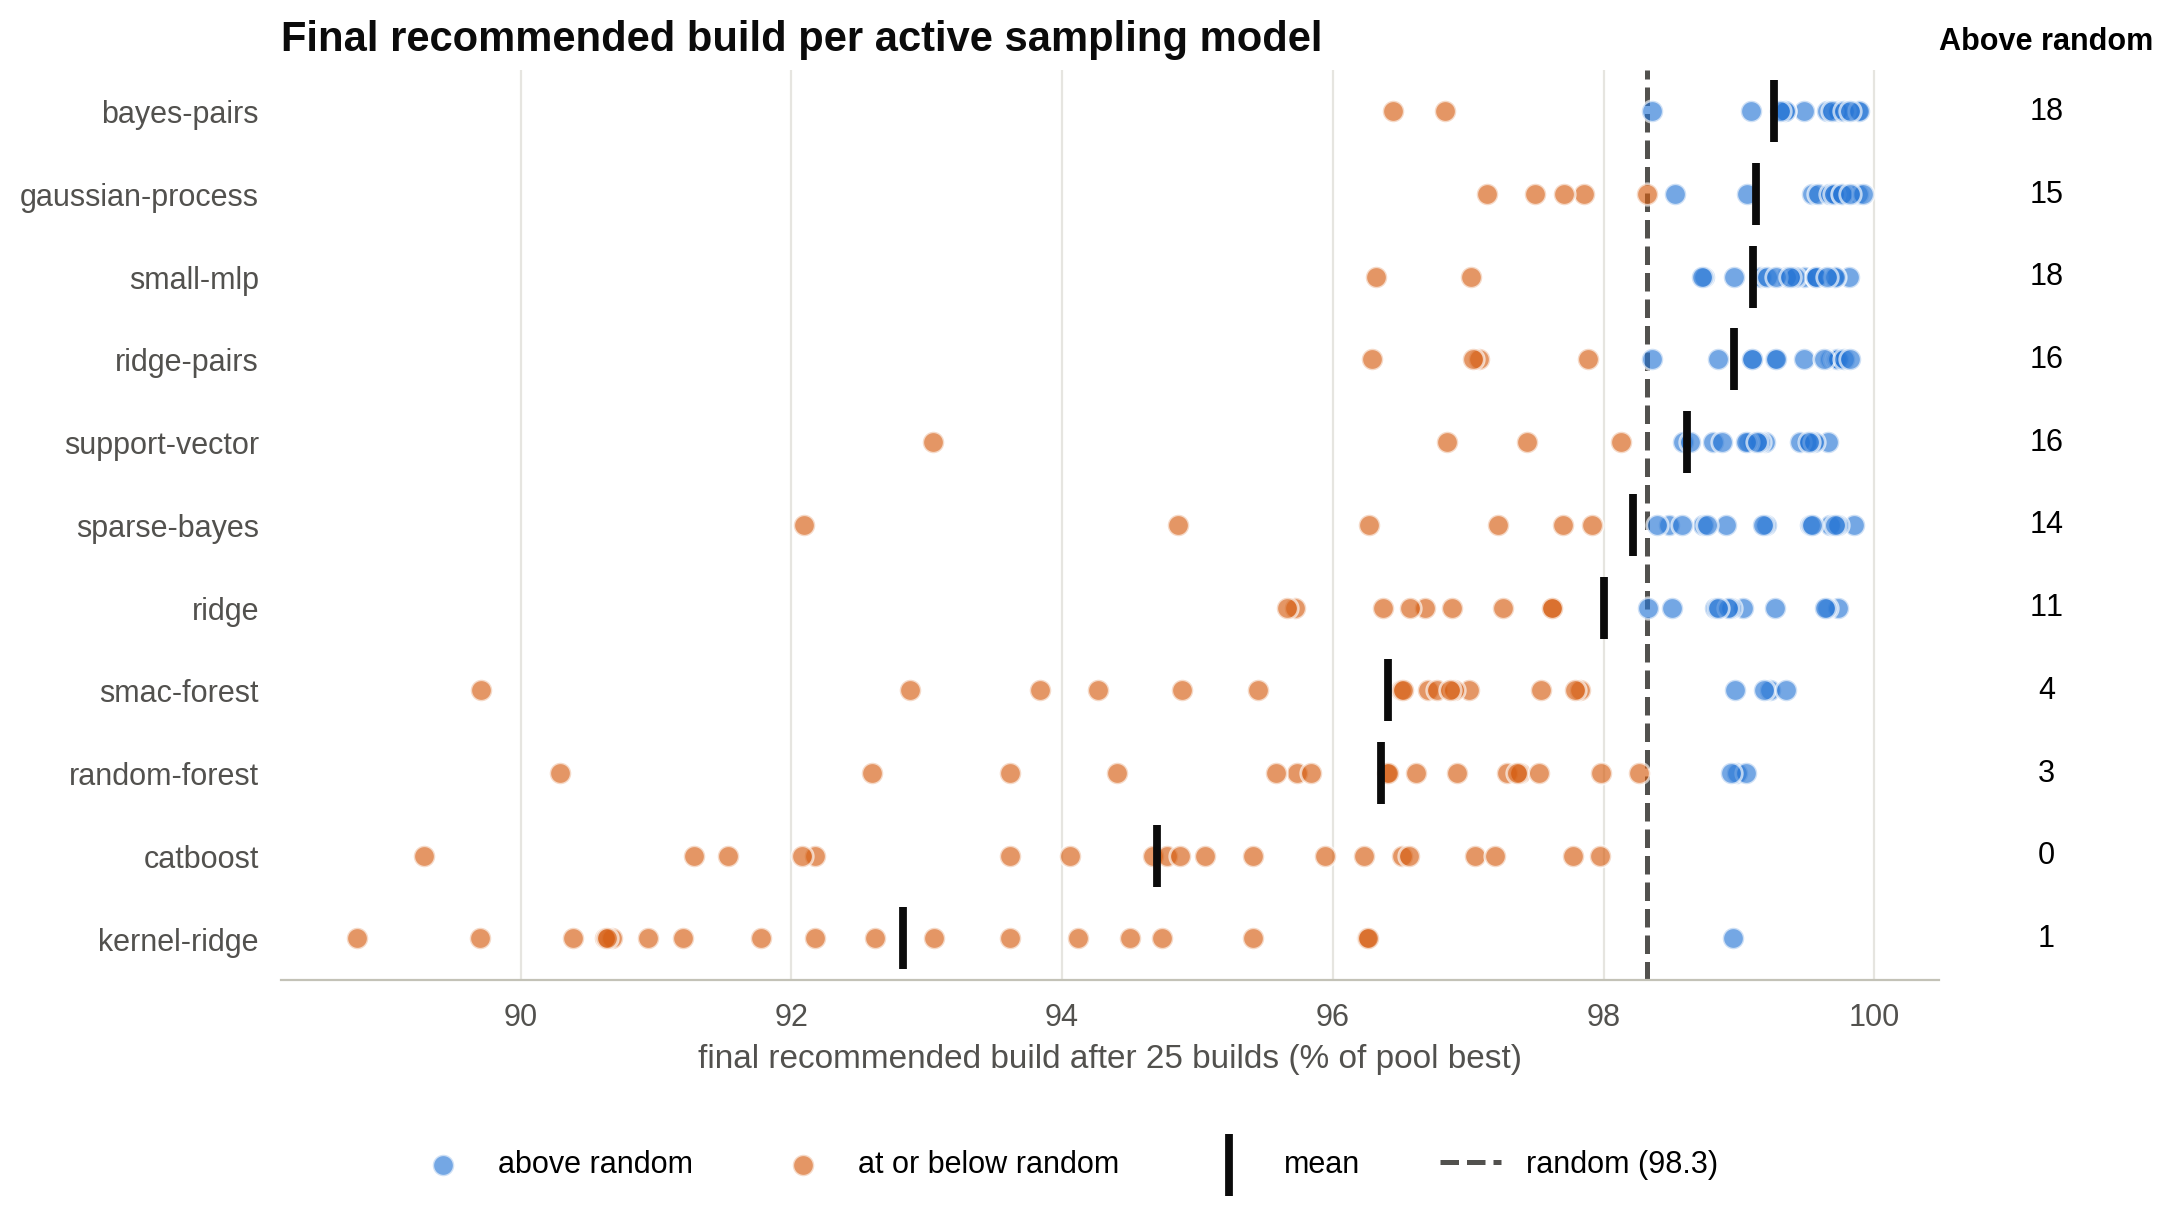

In [8]:
# Figure 5: final recommended build per local model
rec = warm_platform.groupby(["pretrained", "local"])["rec@25"].mean().reset_index()
order = rec.groupby("local")["rec@25"].mean().sort_values().index
row = {name: i for i, name in enumerate(order)}
fig, ax = plt.subplots(figsize=(11.2, 6.5))
fig.subplots_adjust(left=0.15, right=0.89, top=0.91, bottom=0.21)

reference = random_mean["eval"]["best@25"].mean()
above_random = rec["rec@25"] > reference
for points, color, label in (
    (rec[above_random], SERIES[0], "above random"),
    (rec[~above_random], "#d65e12", "at or below random"),
):
    ax.scatter(points["rec@25"], points.local.map(row), s=60, color=color, alpha=0.65,
               edgecolor=SURFACE, linewidth=1, zorder=3, label=label)
mean = rec.groupby("local")["rec@25"].mean()
ax.scatter(mean, mean.index.map(row), marker="|", s=500, color=INK, linewidth=2.8,
           zorder=4, label="mean")
counts = above_random.groupby(rec["local"]).sum().reindex(order)
ax.text(1.065, 1.015, "Above random", transform=ax.transAxes,
        ha="center", va="bottom", fontsize=11, weight="bold")
for name, count in counts.items():
    ax.text(1.065, row[name], str(count), transform=ax.get_yaxis_transform(),
            ha="center", va="center", fontsize=11)
ax.axvline(reference, color=INK2, ls="--", lw=1.8, label=f"random ({reference:.1f})")

ax.set_yticks(range(len(order)), order)
ax.set_xticks([90, 92, 94, 96, 98, 100])
ax.set_ylim(-0.5, len(order) - 0.5)
ax.tick_params(axis="both", length=0, labelsize=11, pad=8)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("final recommended build after 25 builds (% of pool best)", fontsize=12)
ax.set_title("Final recommended build per active sampling model",
             loc="left", fontsize=15, weight="bold", pad=7)
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.035), ncol=4, frameon=False, fontsize=11, columnspacing=2.6)
plt.show()

## 4. Robustness of the historical model

### 4a. Start builds

Quality of the historical model's 2 start builds, refitted with `random_state` 0–4 on both snapshots. `hardware-three-way` is excluded because it is too expensive to fit.

In [9]:
HISTORICAL = [name for name in MODEL_TYPES if name not in ("random", "hardware-three-way")]
starts = pd.concat({label: ms.cached(CACHE / f"start-picks-{data}-{HIST_SEEDS}.csv",
                                     lambda table=table: ms.start_picks(table, HISTORICAL, HIST_SEEDS, JOBS), RECOMPUTE)
                    for label, (data, table) in SNAPSHOTS.items()}, names=["snapshot"]).reset_index(0)

hard_starts = starts[starts.platform.isin(HARD)].groupby(["snapshot", "historical", "seed"]).top2.mean()
summary = hard_starts.groupby(["historical", "snapshot"]).agg(["mean", "min", "max"]).unstack("snapshot")
# display(summary.round(1))

VARYING = sorted(starts.groupby(["snapshot", "historical", "platform"]).spearman
                 .apply(lambda s: s.round(10).nunique() > 1).groupby("historical").any().loc[lambda s: s].index)
print("seed-dependent historical models:", VARYING)

seed-dependent historical models: ['catboost', 'gaussian-process', 'no-hardware-catboost', 'no-hardware-gaussian-process', 'no-hardware-random-forest', 'no-hardware-small-mlp', 'random-forest', 'smac-forest', 'small-mlp']


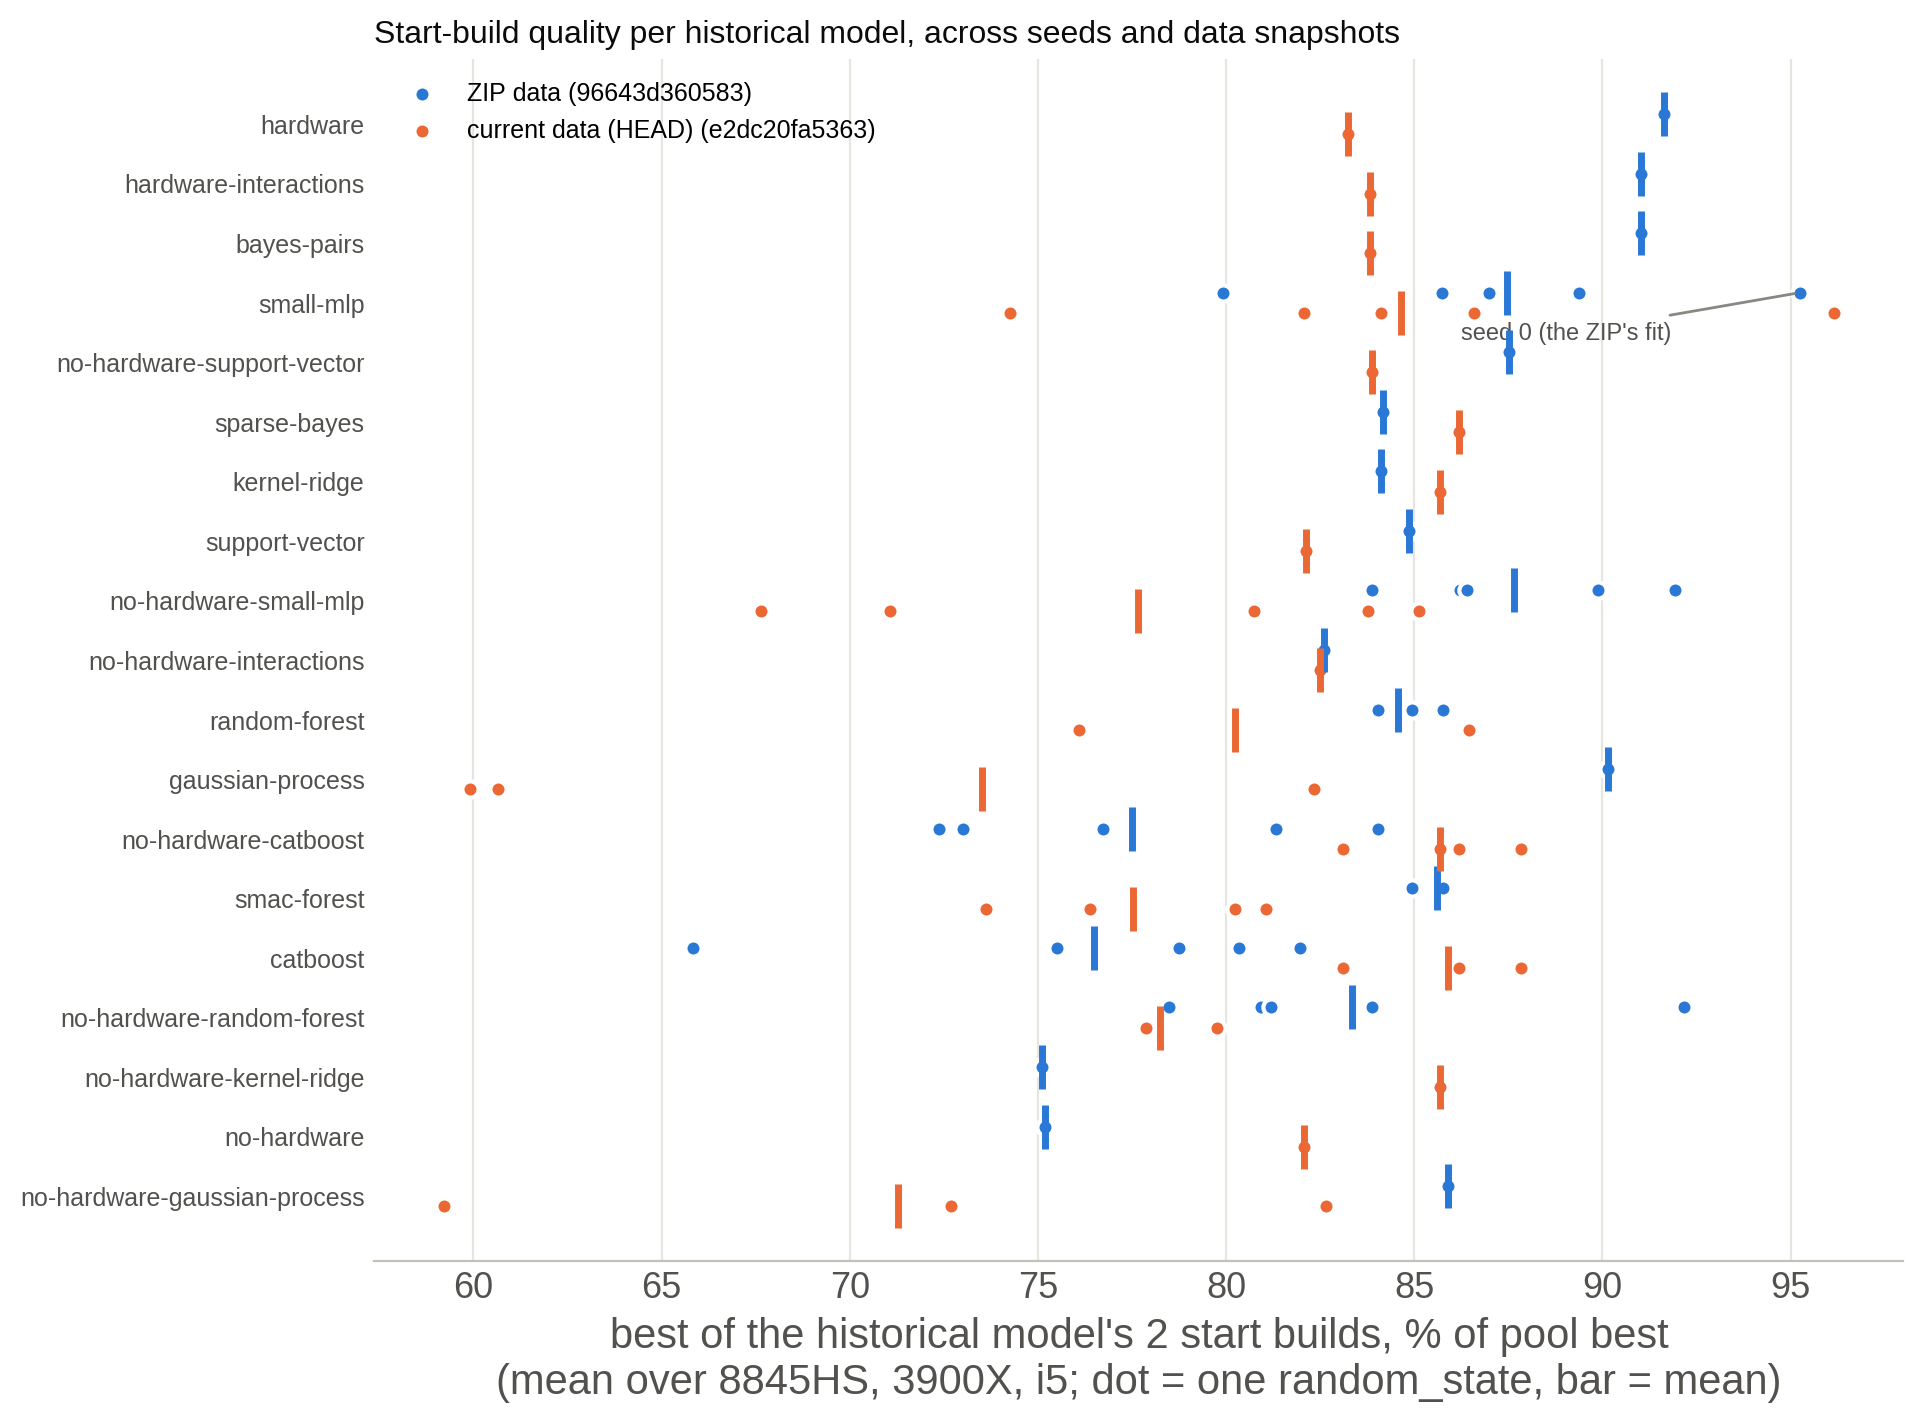

In [10]:
# Figure 3: start-build quality per seed and snapshot
points = hard_starts.reset_index()
order = points.groupby("historical").top2.mean().sort_values().index
row = {name: i for i, name in enumerate(order)}
fig, ax = plt.subplots(figsize=(9.5, 7), layout="constrained")
for (label, color, offset) in [("eval", SERIES[0], 0.17), ("current", SERIES[1], -0.17)]:
    data = points[points.snapshot == label]
    ax.scatter(data.top2, data.historical.map(row) + offset, s=34, color=color, edgecolor=SURFACE,
               linewidth=1.5, zorder=3, label=f"{NAMES[label]} ({COMMITS[label]})")
    mean = data.groupby("historical").top2.mean()
    ax.scatter(mean, mean.index.map(row) + offset, marker="|", s=260, color=color, linewidth=2.5, zorder=4)
lucky = points[(points.snapshot == "eval") & (points.historical == "small-mlp") & (points.seed == 0)].top2.iloc[0]
ax.annotate("seed 0 (the ZIP's fit)", (lucky, row["small-mlp"] + 0.17), xytext=(lucky - 9, row["small-mlp"] - 0.62),
            fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color="#898781", lw=1))
ax.set_yticks(range(len(order)), order, fontsize=9)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("best of the historical model's 2 start builds, % of pool best\n"
              "(mean over 8845HS, 3900X, i5; dot = one random_state, bar = mean)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.set_title("Start-build quality per historical model, across seeds and data snapshots", loc="left", fontsize=11.5)
plt.show()

### 4b. Full replays of a shortlist

The shortlist is the top 7 by ZIP AUC plus the top 3 by start builds, replayed with `LOCALS`. Seed-dependent models are run with seeds 0–4.

In [11]:
by_eval = ranking.drop("none").groupby("pretrained").auc.mean().nlargest(7).index
by_start = hard_starts.groupby(["snapshot", "historical"]).mean().groupby("historical").mean().nlargest(3).index
SHORTLIST = list(dict.fromkeys([*by_eval, *by_start]))
print("shortlist:", SHORTLIST)

def replay_cached(label, historical):
    data, table = SNAPSHOTS[label]
    tag = ",".join(sorted(historical)) + "|" + ",".join(LOCALS) + "|" + ",".join(VARYING)
    name = f"replay-{data}-{HIST_SEEDS}-{hashlib.sha1(tag.encode()).hexdigest()[:8]}.csv"
    frame = ms.cached(CACHE / name, lambda: ms.replay(table, historical, LOCALS, HIST_SEEDS, JOBS, vary=VARYING), RECOMPUTE)
    return ms.with_auc(frame)

eval_replay = replay_cached("eval", [h for h in SHORTLIST if h in VARYING])
current_replay = replay_cached("current", SHORTLIST)

shortlist: ['small-mlp', 'no-hardware-random-forest', 'no-hardware-support-vector', 'no-hardware-interactions', 'gaussian-process', 'support-vector', 'bayes-pairs', 'hardware', 'hardware-interactions']


## 5. Final ranking

A pair qualifies only if its Δ AUC vs random is positive on both snapshots. Qualifying pairs are ranked by Δ AUC on the current data (what live sampling trains on), and the top 5 contain one pair per historical model.

In [12]:
def platform_scores(frame):
    return frame.groupby(["historical", "local", "platform"])[METRICS].mean()

zip_det = sessions[(sessions.pretrained.isin(SHORTLIST)) & (~sessions.pretrained.isin(VARYING))
                   & (sessions.local.isin([ms.local_family(l) for l in LOCALS]))]
zip_det = zip_det.rename(columns={"pretrained": "historical"})
scores = {"eval": pd.concat([platform_scores(zip_det), platform_scores(eval_replay)]),
          "current": platform_scores(current_replay)}

def versus_random(frame, label):
    delta = frame[METRICS] - random_mean[label].reindex(frame.index.get_level_values("platform"))[METRICS].to_numpy()
    grouped = delta.groupby(["historical", "local"])
    out = grouped.mean().add_prefix("Δ ")
    out["worst platform Δ auc"] = grouped["auc"].min()
    return pd.concat({label: out}, axis=1)

final = pd.concat([versus_random(scores["eval"], "eval"), versus_random(scores["current"], "current")], axis=1)
final[("both", "positive")] = (final[("eval", "Δ auc")] > 0) & (final[("current", "Δ auc")] > 0)
final = final.sort_values([("both", "positive"), ("current", "Δ auc")], ascending=False)
final[("eval", "auc")] = scores["eval"].auc.groupby(["historical", "local"]).mean()
final[("current", "auc")] = scores["current"].auc.groupby(["historical", "local"]).mean()
# display(final.round(2))
qualifying = final[final[("both", "positive")]]
TOP = qualifying.groupby(level="historical", sort=False).head(1).head(5).index.tolist()
display(Markdown("**Top 5:** " + "; ".join(f"{i}. `{h} → {l}`" for i, (h, l) in enumerate(TOP, 1))))

**Top 5:** 1. `no-hardware-interactions → bayes-pairs`; 2. `small-mlp → bayes-pairs`; 3. `support-vector → gaussian-process`; 4. `bayes-pairs → gaussian-process`; 5. `gaussian-process → gaussian-process`

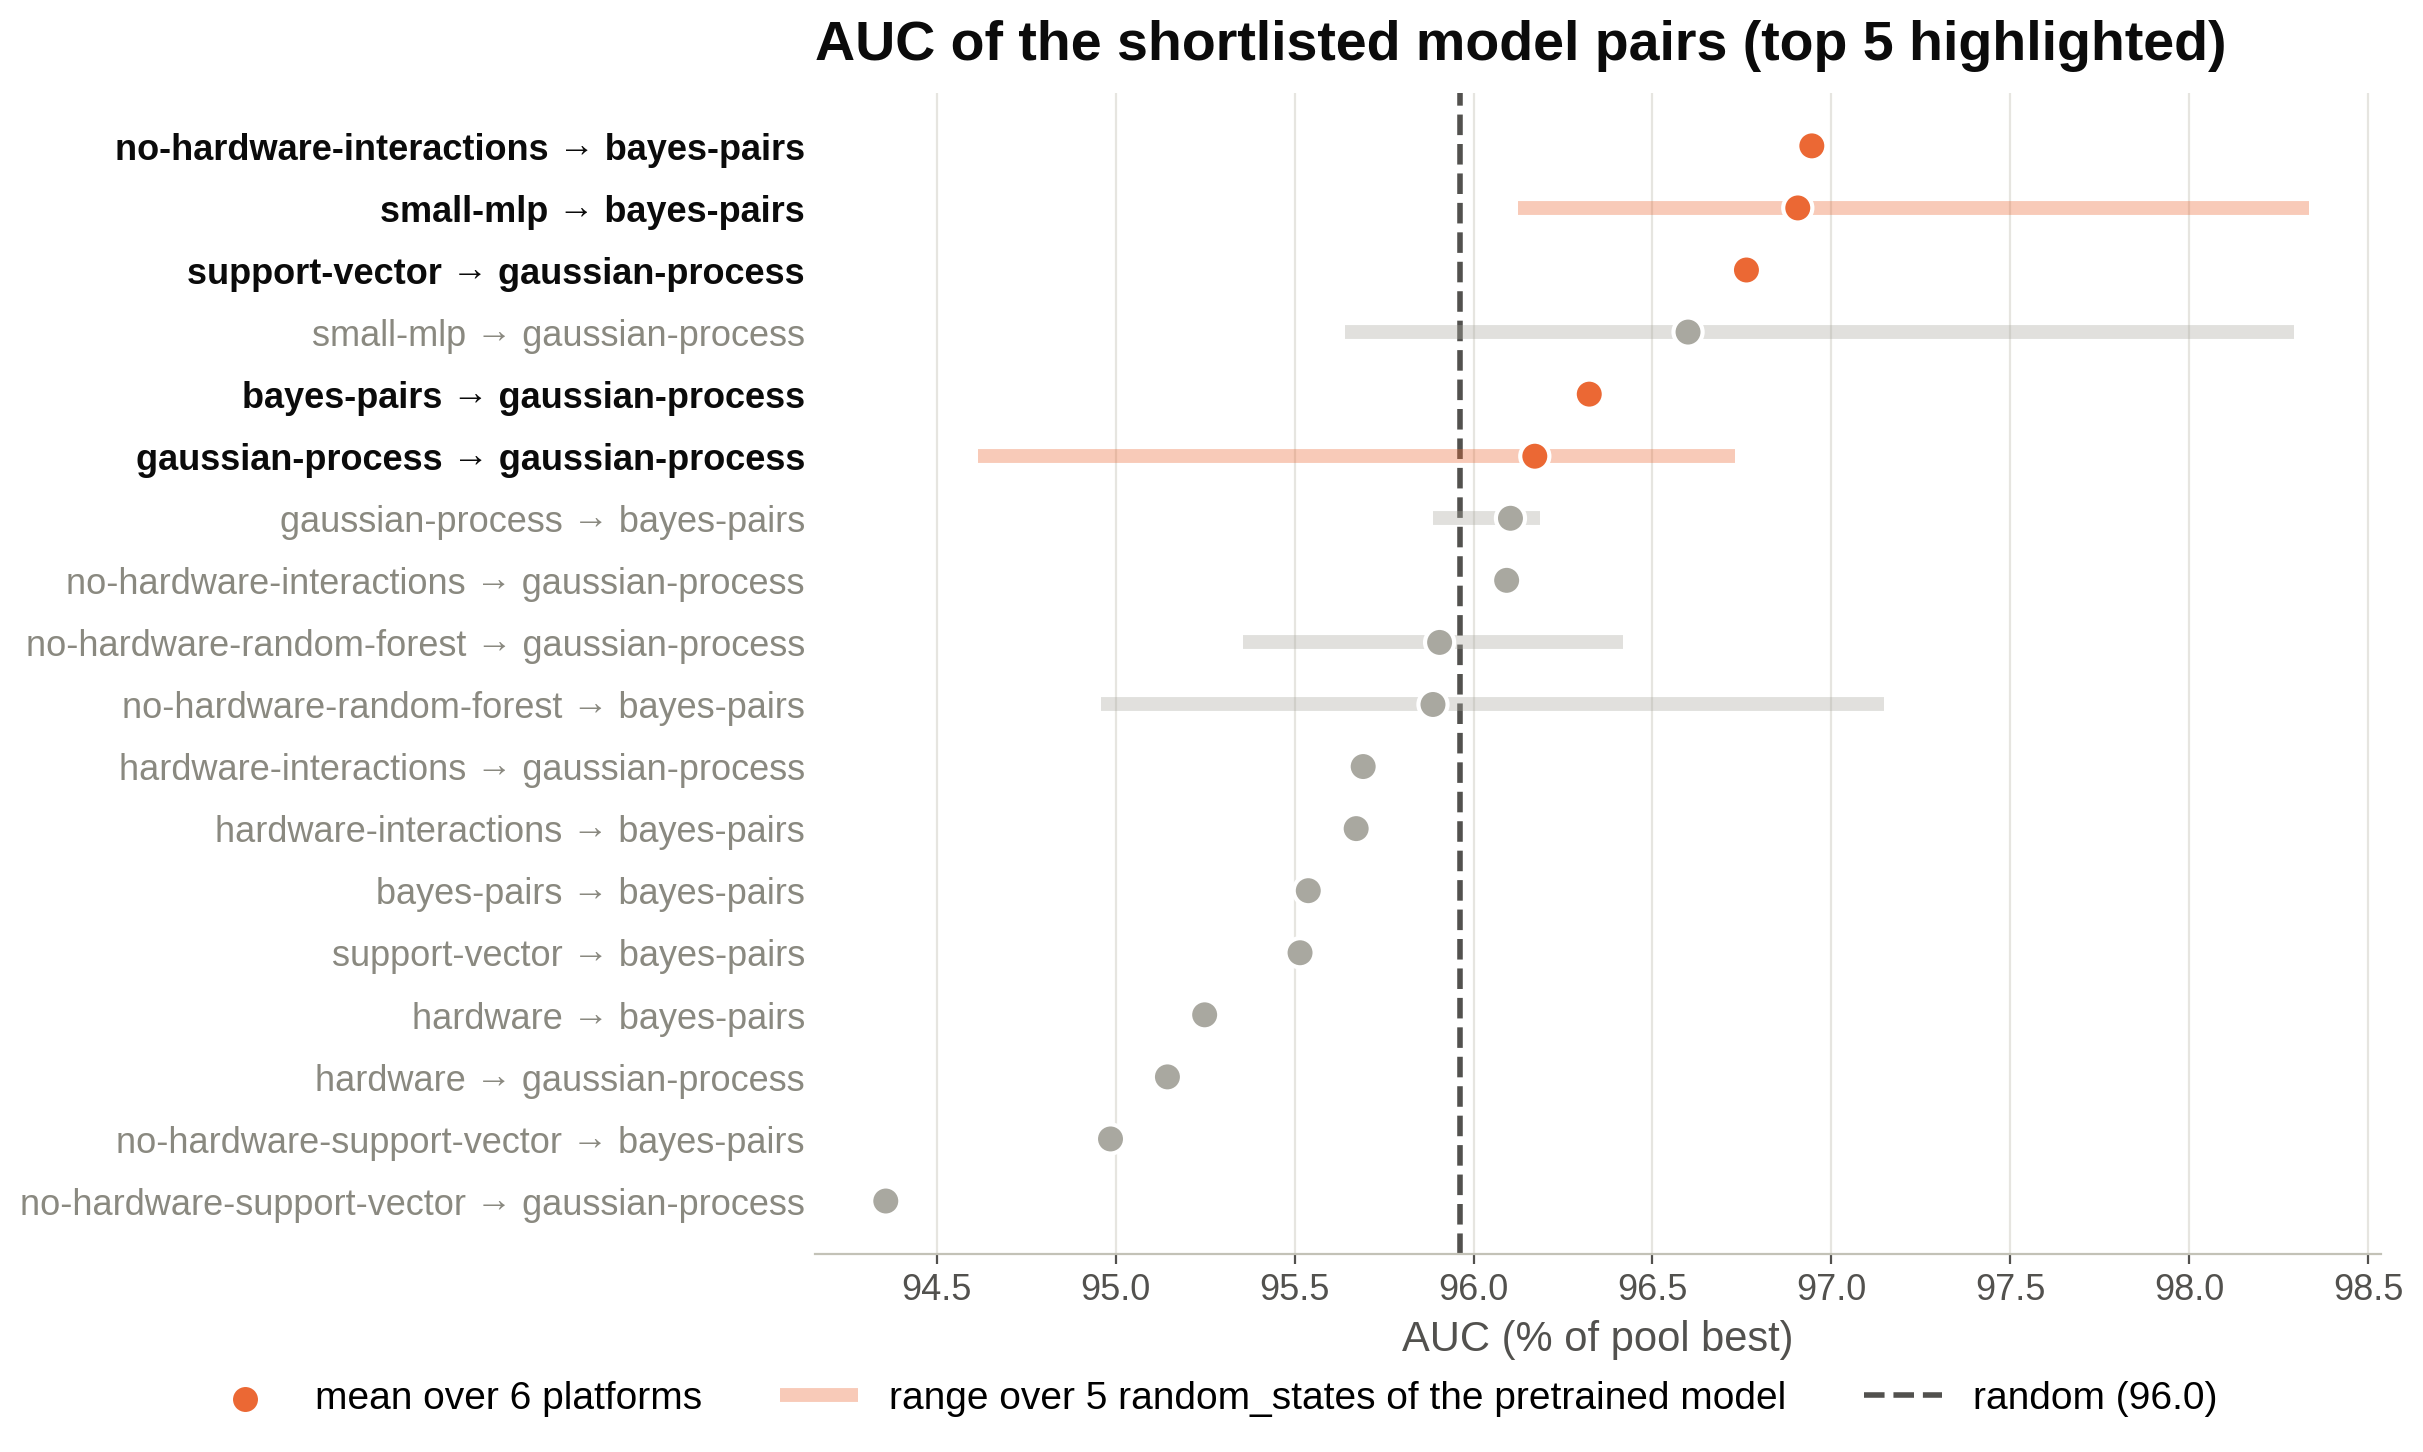

In [13]:
# Figure 4: AUC of the shortlisted pairs on the current data
pairs = final.index.tolist()[::-1]
y = {pair: i for i, pair in enumerate(pairs)}
colour = {pair: SERIES[1] if pair in TOP else "#a9a8a0" for pair in pairs}
fig, ax = plt.subplots(figsize=(SLIDE[0], 7.2), layout="constrained")
values = final[("current", "auc")]
seed_auc = current_replay[current_replay.historical.isin(VARYING)].groupby(["historical", "local", "seed"]).auc.mean()
for pair, spread in seed_auc.groupby(["historical", "local"]):
    if pair in y:
        ax.hlines(y[pair], spread.min(), spread.max(), color=colour[pair], lw=5, alpha=0.35, zorder=3)
ax.scatter(values, [y[p] for p in values.index], s=110, color=[colour[p] for p in values.index],
           edgecolor=SURFACE, linewidth=1.5, zorder=4)
dots = ax.scatter([], [], s=110, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5)
spread_key = ax.hlines([], 0, 0, color=SERIES[1], lw=5, alpha=0.35)
baseline = ax.axvline(random_mean["current"].auc.mean(), color=INK2, ls="--", lw=2)
ax.set_yticks(range(len(pairs)), [f"{h} → {l}" for h, l in pairs])
for tick, pair in zip(ax.get_yticklabels(), pairs):
    if pair in TOP:
        tick.set_fontweight("bold")
        tick.set_color(INK)
    else:
        tick.set_color("#8a8980")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("AUC (% of pool best)")
fig.legend([dots, spread_key, baseline],
           ["mean over 6 platforms", "range over 5 random_states of the pretrained model",
            f"random ({random_mean['current'].auc.mean():.1f})"],
           loc="outside lower center", ncol=3, frameon=False)
ax.set_title("AUC of the shortlisted model pairs (top 5 highlighted)", **TITLE_STYLE)
plt.show()

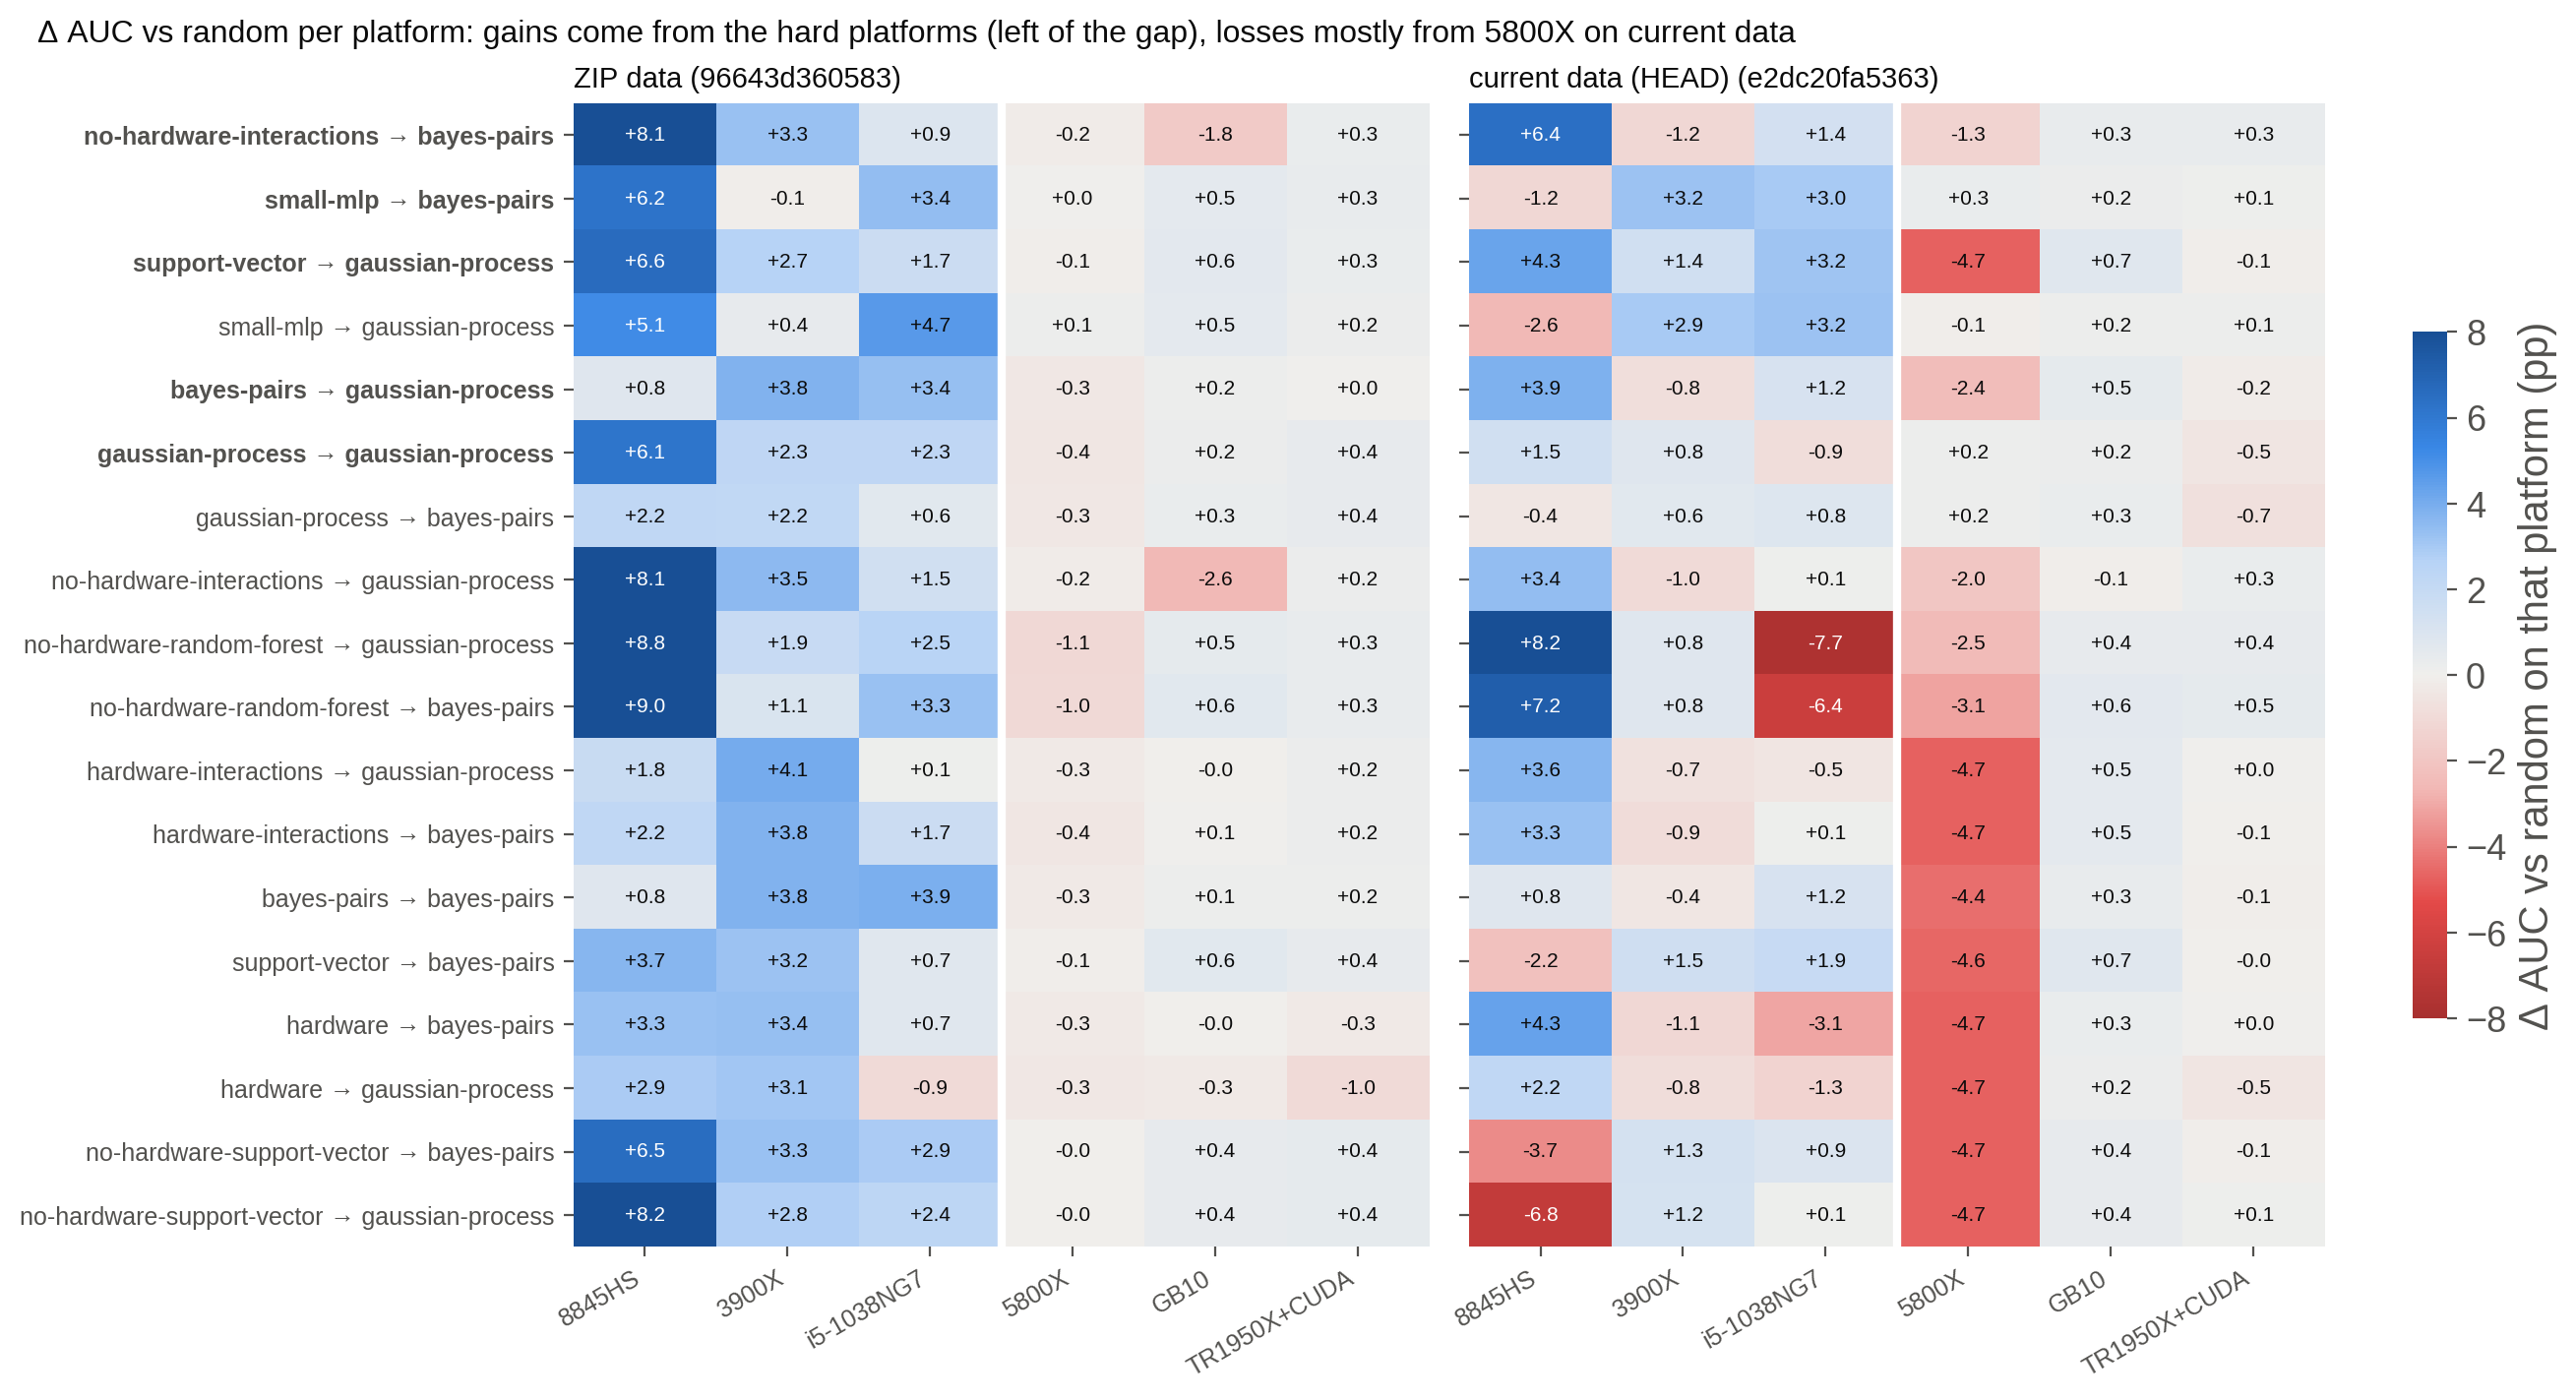

In [14]:
# Figure 6: Δ AUC vs random per platform
diverging = LinearSegmentedColormap.from_list(
    "red-gray-blue", ["#a8302f", "#e34948", "#f2b8b5", "#f0efec", "#b7d3f6", "#3987e5", "#184f95"])
platform_order = HARD + [p for p in random_mean["eval"].index if p not in HARD]
fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained", sharey=True)
for ax, label in zip(axes, ["eval", "current"]):
    delta = (scores[label].auc - random_mean[label].auc.reindex(scores[label].index.get_level_values("platform")).to_numpy())
    grid = delta.unstack("platform").reindex(index=final.index, columns=platform_order)
    image = ax.imshow(grid.to_numpy(), cmap=diverging, vmin=-8, vmax=8, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            value = grid.iat[i, j]
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(value) > 5 else INK)
    ax.set_xticks(range(len(platform_order)), platform_order, rotation=30, ha="right", fontsize=9)
    ax.axvline(len(HARD) - 0.5, color=SURFACE, lw=3)
    ax.set_title(f"{NAMES[label]} ({COMMITS[label]})", loc="left", fontsize=10.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_yticks(range(len(final)), [f"{h} → {l}" for h, l in final.index], fontsize=9)
for tick, pair in zip(axes[0].get_yticklabels(), final.index):
    if pair in TOP:
        tick.set_fontweight("bold")
bar = fig.colorbar(image, ax=axes, shrink=0.6)
bar.set_label("Δ AUC vs random on that platform (pp)")
bar.outline.set_visible(False)
fig.suptitle("Δ AUC vs random per platform: gains come from the hard platforms (left of the gap), "
             "losses mostly from 5800X on current data", x=0.01, ha="left", fontsize=11.5, color=INK)
plt.show()

In [15]:
# Cold start on current data, one model per local family
COLD = ["no-hardware", "no-hardware-interactions", "no-hardware-random-forest", "no-hardware-catboost",
        "no-hardware-gaussian-process", "no-hardware-kernel-ridge", "no-hardware-support-vector",
        "no-hardware-small-mlp", "smac-forest", "bayes-pairs", "sparse-bayes"]
COLD_SEEDS = 3
cold_current = ms.with_auc(ms.cached(CACHE / f"cold-{current_data}-{COLD_SEEDS}.csv",
                                     lambda: ms.cold_replay(current_table, COLD, COLD_SEEDS, JOBS), RECOMPUTE))
cold_bands = {"eval": sessions[(sessions.pretrained == "none") & (sessions.model != "random")],
              "current": cold_current}
cold_summary = pd.DataFrame({
    label: frame.groupby(["local", "platform"]).auc.mean().groupby("local").mean() - random_mean[label].auc.mean()
    for label, frame in cold_bands.items()}).add_prefix("Δ auc vs random, ")
# display(cold_summary.sort_values(cold_summary.columns[1], ascending=False))

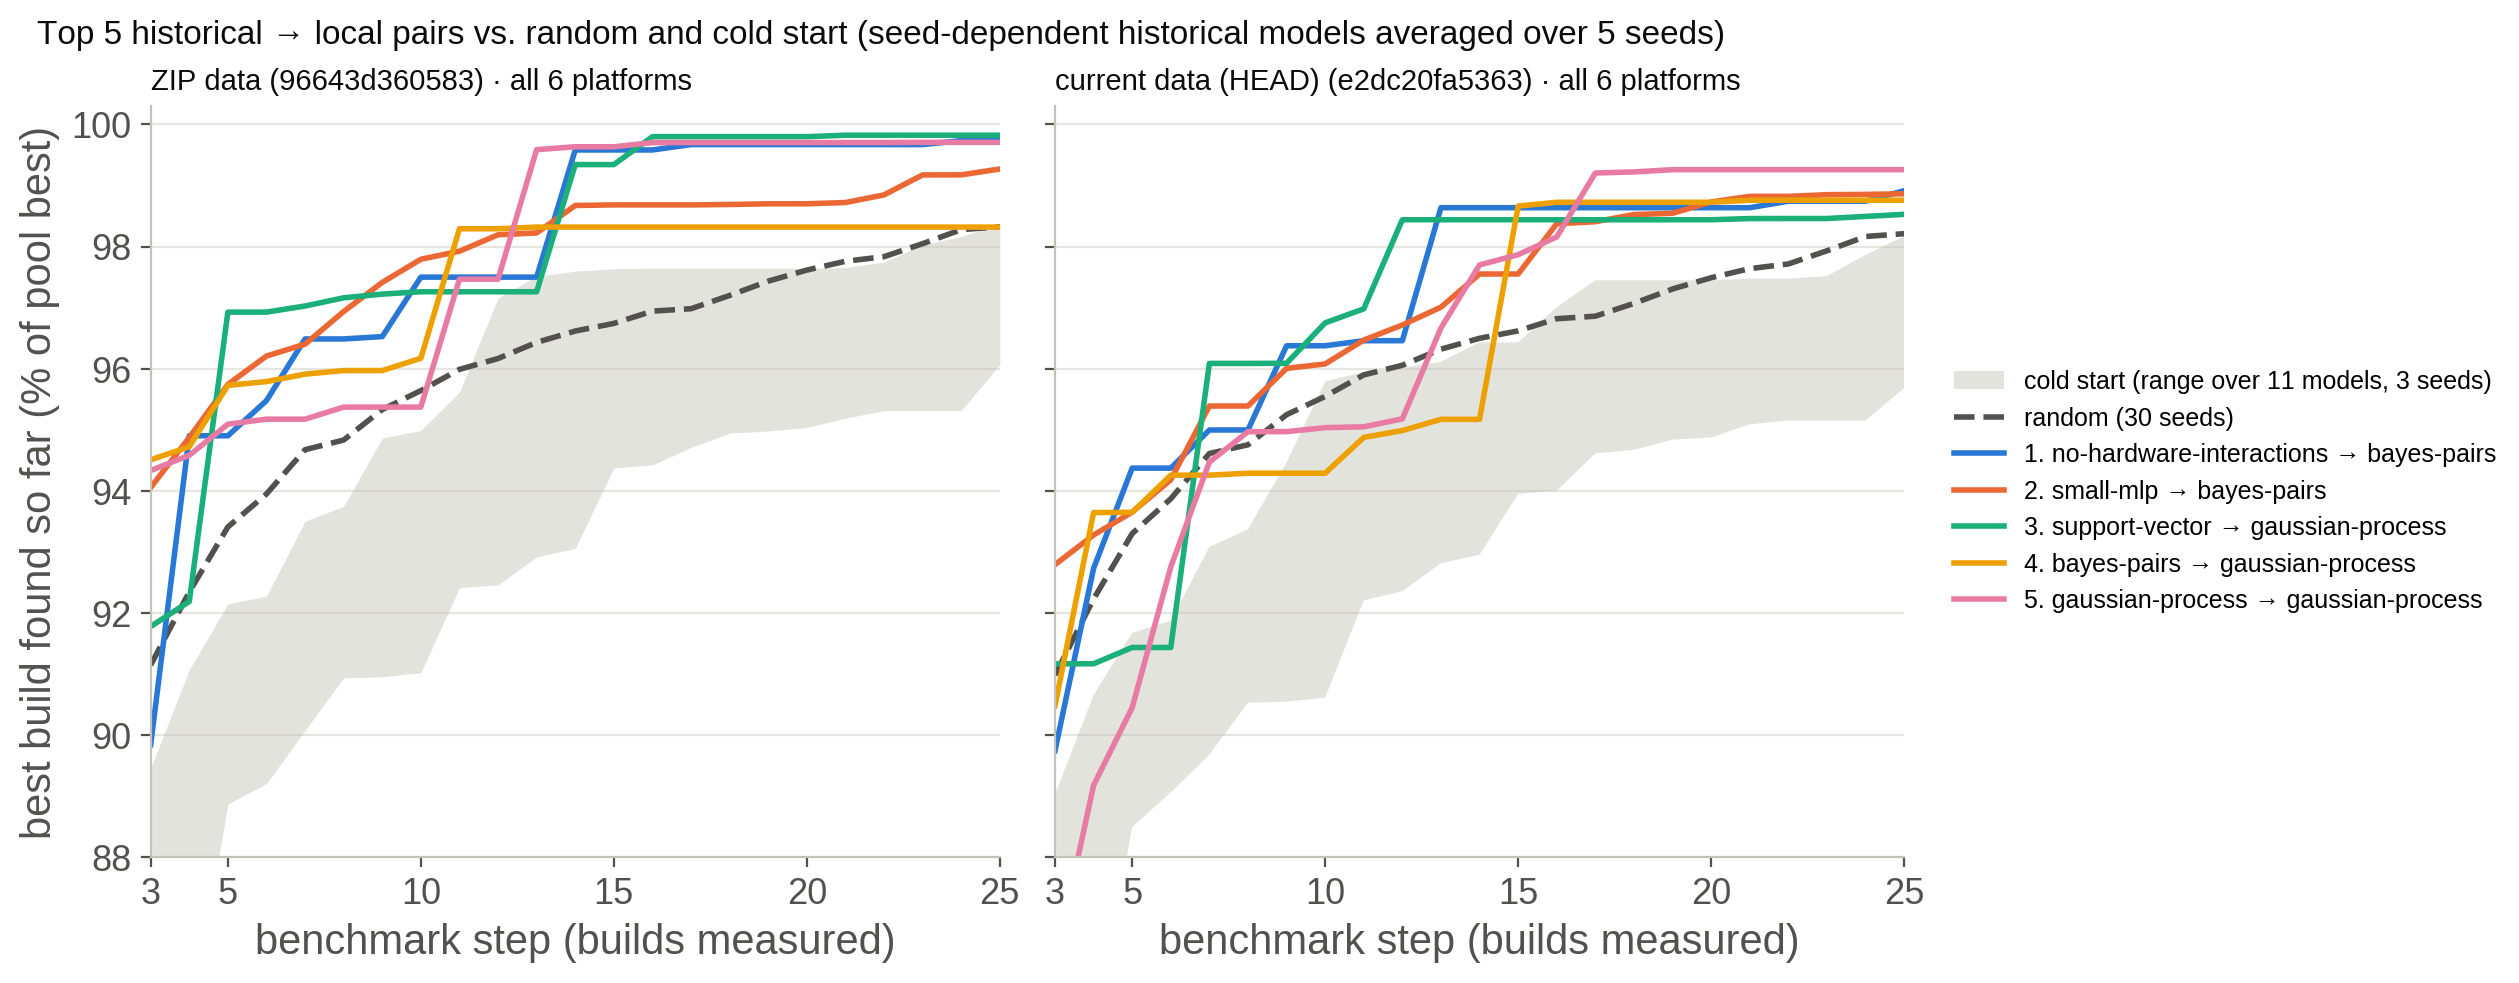

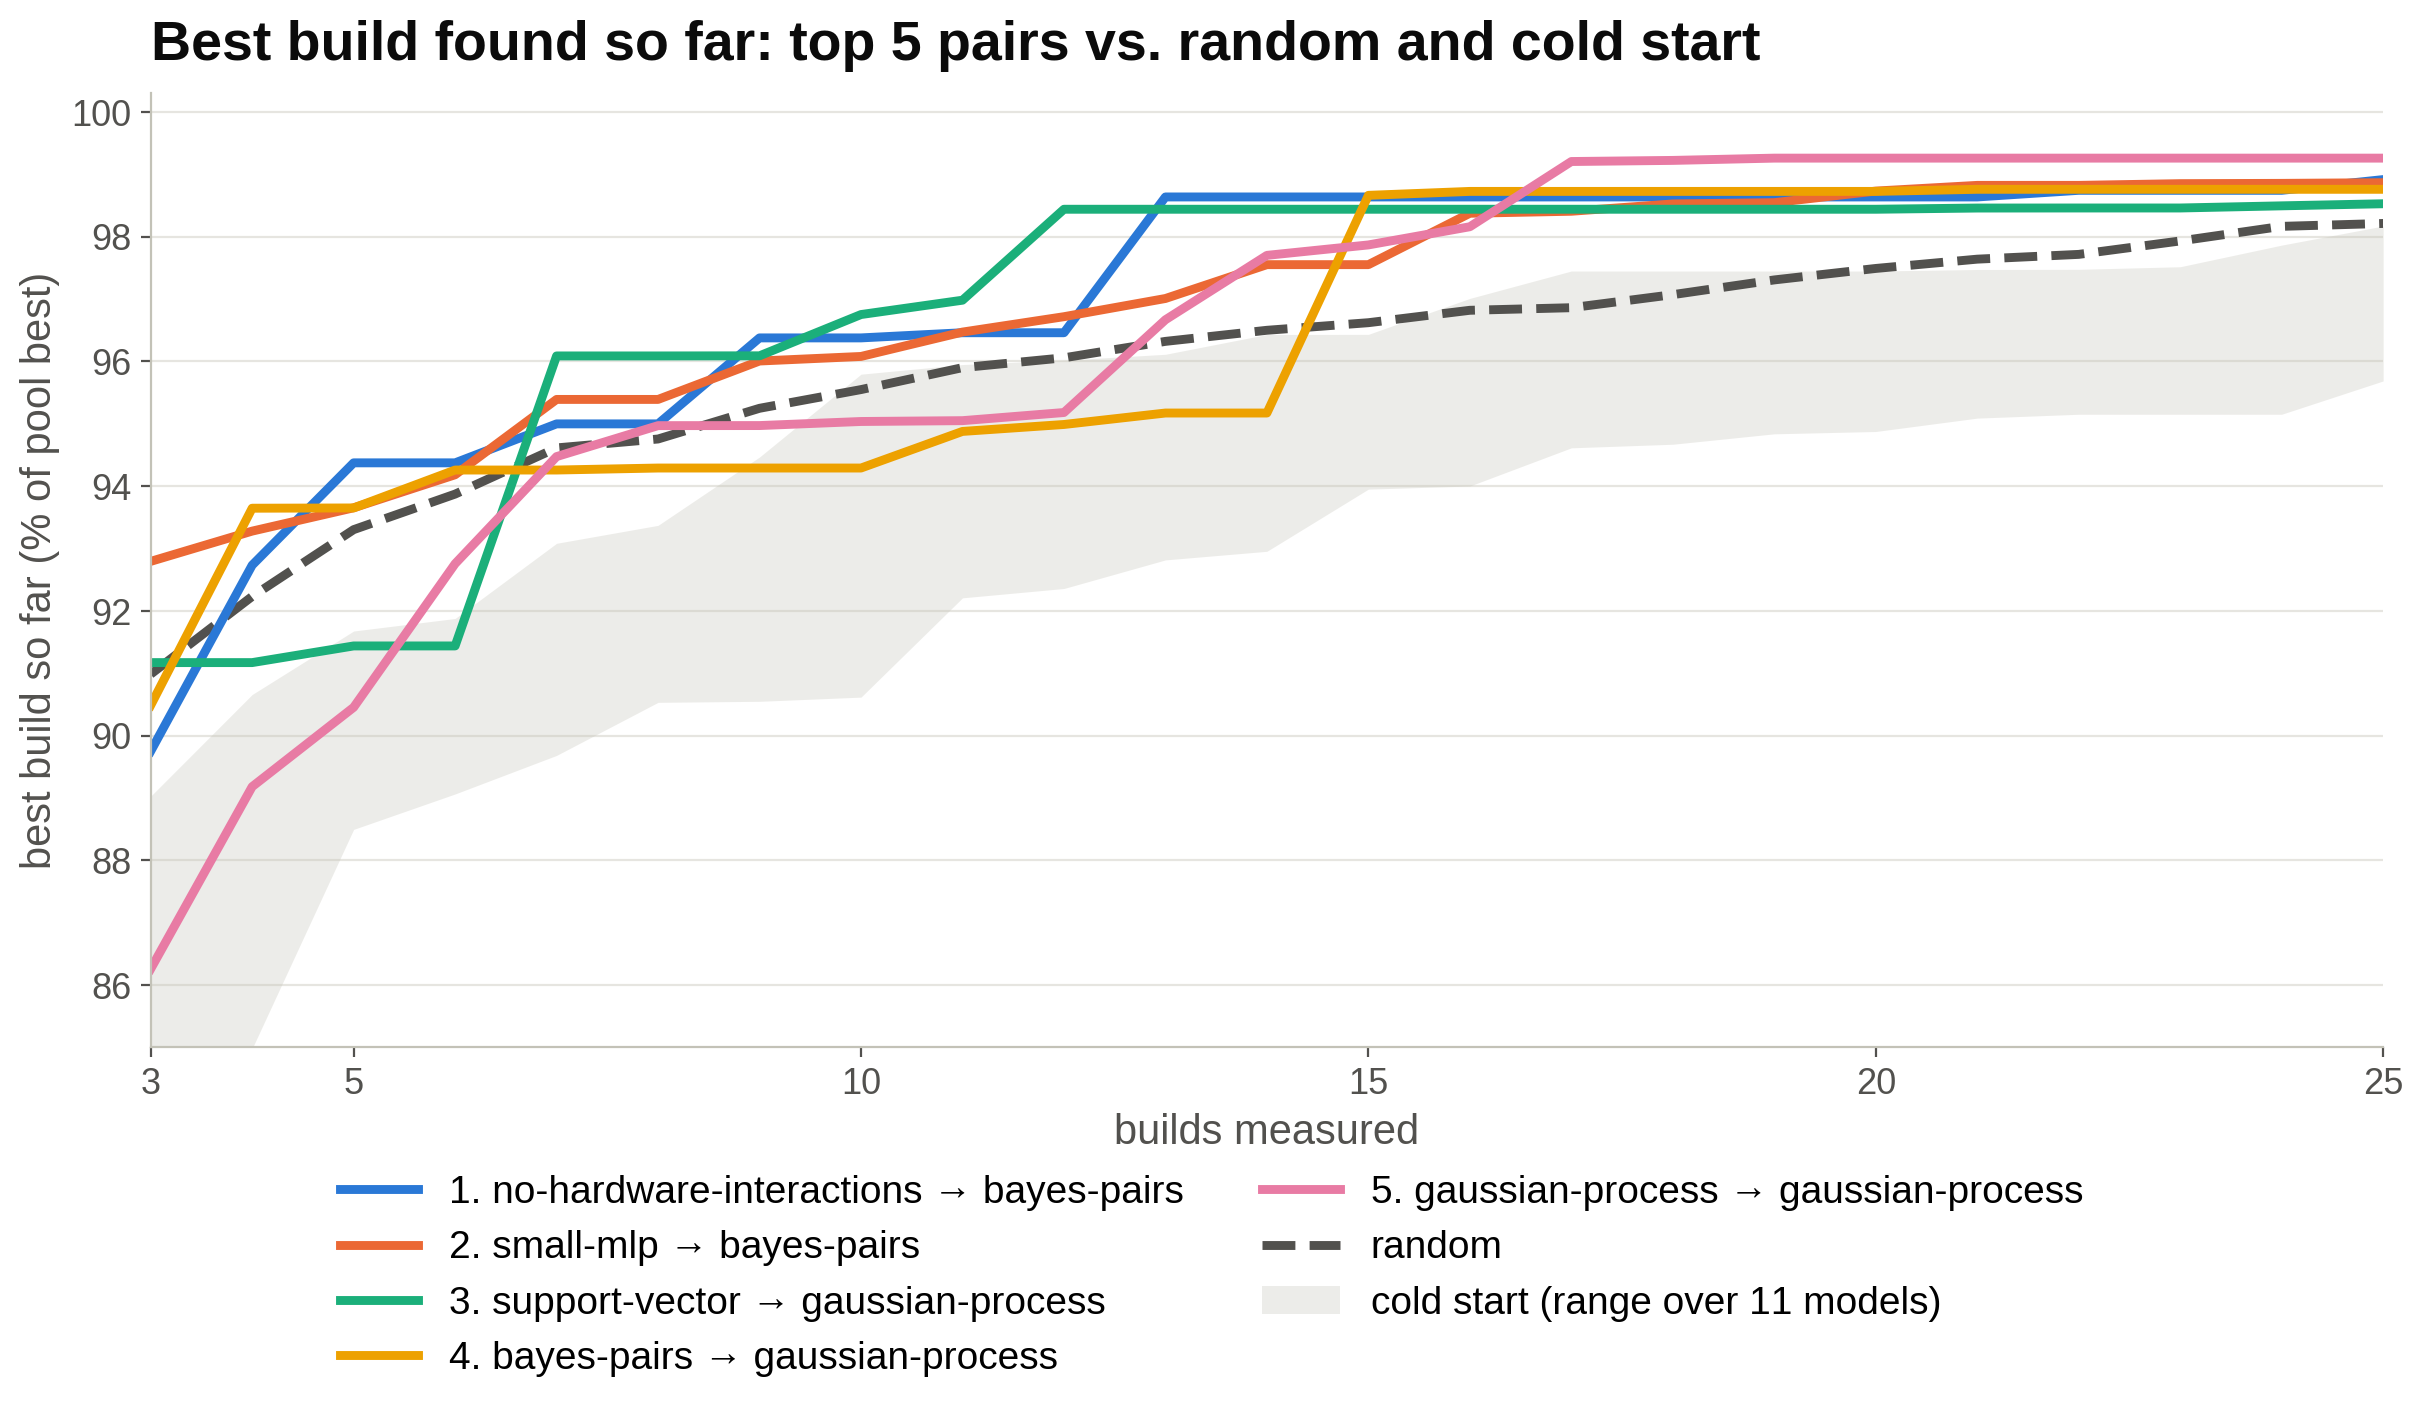

In [16]:
# Figures 1 / 1b: best build so far for the top 5
def curve(frame):
    return frame.groupby("platform")[ms.BEST].mean().mean().to_numpy()

def draw_panel(ax, label, data):
    band = cold_bands[label].groupby(["local", "platform"])[ms.BEST].mean().groupby("local").mean()
    ax.fill_between(ms.STEPS, band.min(), band.max(), color=NEUTRAL, alpha=0.45, lw=0,
                    label="cold start (range over 11 models, 3 seeds)")
    ax.plot(ms.STEPS, curve(random[label]), color=INK2, lw=2, ls="--", label="random (30 seeds)")
    for i, (historical, local) in enumerate(TOP):
        pair = data[(data.historical == historical) & (data.local == local)]
        ax.plot(ms.STEPS, curve(pair), color=SERIES[i], lw=2, label=f"{i + 1}. {historical} → {local}")
    ax.set_title(f"{NAMES[label]} ({COMMITS[label]}) · all 6 platforms", loc="left", fontsize=10.5)
    ax.set_xlabel("benchmark step (builds measured)")
    ax.set_xlim(3, 25)
    ax.set_xticks([3, 5, 10, 15, 20, 25])
    ax.set_ylim(88, 100.3)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)

TITLE = "Top 5 historical → local pairs vs. random and cold start"
NOTE = "seed-dependent historical models averaged over 5 seeds"
eval_curves = pd.concat([zip_det, eval_replay])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout="constrained", sharey=True)
for ax, (label, data) in zip(axes, [("eval", eval_curves), ("current", current_replay)]):
    draw_panel(ax, label, data)
axes[0].set_ylabel("best build found so far (% of pool best)")
handles = {l: h for ax in axes for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend(handles.values(), handles.keys(), loc="outside right center", frameon=False, fontsize=9)
fig.suptitle(f"{TITLE} ({NOTE})", x=0.01, ha="left", fontsize=12, color=INK)
plt.show()

fig, ax = plt.subplots(figsize=(SLIDE[0], 7), layout="constrained")
draw_panel(ax, "current", current_replay)
for line in ax.get_lines():
    line.set_linewidth(3.2)
ax.collections[0].set_alpha(0.3)
lowest = min(min(line.get_ydata()) for line in ax.get_lines()) - 0.5
ax.set_ylim(min(88, np.floor(lowest)), 100.3)
ax.set_title("Best build found so far: top 5 pairs vs. random and cold start", **TITLE_STYLE)
ax.set_xlabel("builds measured")
ax.set_ylabel("best build so far (% of pool best)")
handles, labels = ax.get_legend_handles_labels()
labels[:2] = ["cold start (range over 11 models)", "random"]
order = list(range(2, len(labels))) + [1, 0]   # pairs first, then random and cold start
fig.legend([handles[k] for k in order], [labels[k] for k in order], loc="outside lower center", ncol=2, frameon=False)
plt.show()

## 6. How certain is the ranking?

Current data only. The 95 % interval comes from resampling the 6 platforms (bootstrap). The pretrained-only baseline measures the historical model's top-n predictions in order, without a local model.

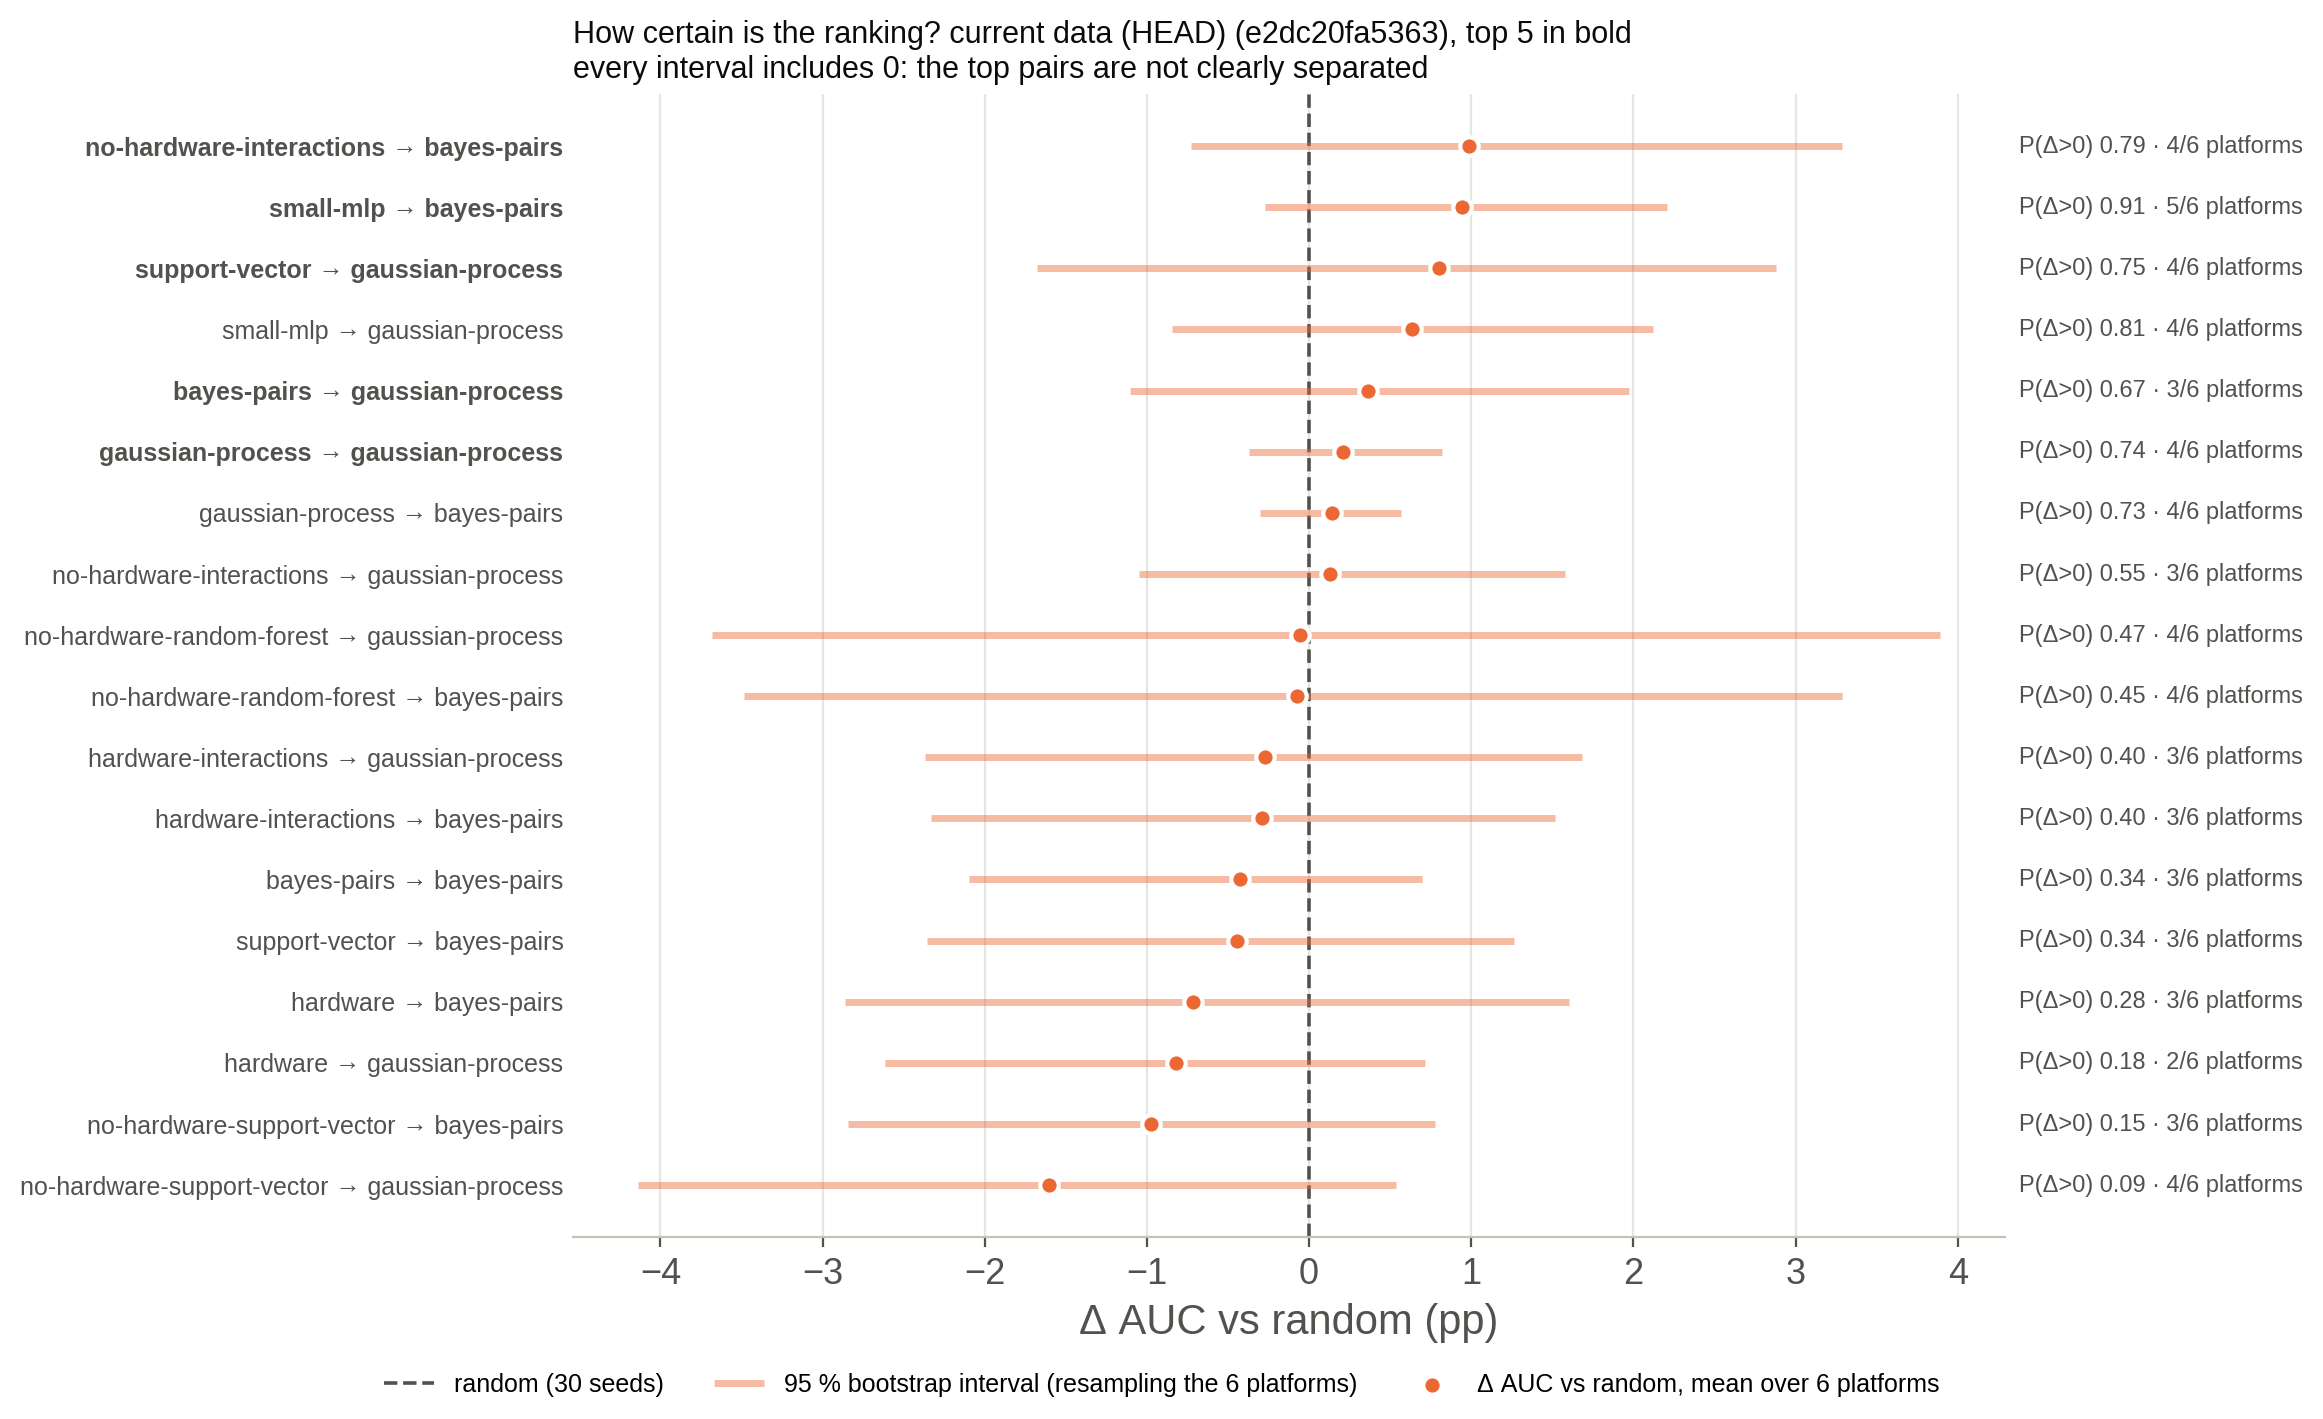

In [17]:
# Figure 7: Δ AUC vs random with a bootstrap interval over platforms (current data)
delta_platform = (scores["current"].auc - random_mean["current"].auc.reindex(
    scores["current"].index.get_level_values("platform")).to_numpy()).unstack("platform").reindex(final.index)
rng = np.random.default_rng(0)
resampled = rng.integers(0, delta_platform.shape[1], size=(5000, delta_platform.shape[1]))
boot = np.stack([delta_platform.to_numpy()[:, idx].mean(axis=1) for idx in resampled])
boot_rank = (-boot).argsort(axis=1).argsort(axis=1)
certainty = pd.DataFrame({
    "Δ auc": delta_platform.mean(axis=1),
    "ci low": np.percentile(boot, 2.5, axis=0), "ci high": np.percentile(boot, 97.5, axis=0),
    "P(Δ>0)": (boot > 0).mean(axis=0), "P(top 3)": (boot_rank < 3).mean(axis=0),
    "platforms > 0": (delta_platform > 0).sum(axis=1)}, index=delta_platform.index)
# display(certainty.round(2))

pairs = final.index.tolist()[::-1]
y = {pair: i for i, pair in enumerate(pairs)}
fig, ax = plt.subplots(figsize=(11.5, 7), layout="constrained")
ax.axvline(0, color=INK2, ls="--", lw=1.3, label="random (30 seeds)")
ax.hlines([y[p] for p in pairs], certainty.loc[pairs, "ci low"], certainty.loc[pairs, "ci high"],
          color=SERIES[1], lw=2.5, alpha=0.45, label="95 % bootstrap interval (resampling the 6 platforms)")
ax.scatter(certainty.loc[pairs, "Δ auc"], [y[p] for p in pairs], s=44, color=SERIES[1], edgecolor=SURFACE,
           linewidth=1.5, zorder=4, label="Δ AUC vs random, mean over 6 platforms")
for pair in pairs:
    row = certainty.loc[pair]
    ax.text(1.01, y[pair], f"P(Δ>0) {row['P(Δ>0)']:.2f} · {int(row['platforms > 0'])}/6 platforms",
            transform=ax.get_yaxis_transform(), va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(pairs)), [f"{h} → {l}" for h, l in pairs], fontsize=9)
for tick, pair in zip(ax.get_yticklabels(), pairs):
    if pair in TOP:
        tick.set_fontweight("bold")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Δ AUC vs random (pp)")
fig.legend(loc="outside lower center", ncol=3, frameon=False, fontsize=9)
ax.set_title(f"How certain is the ranking? {NAMES['current']} ({current_commit}), top 5 in bold\n"
             "every interval includes 0: the top pairs are not clearly separated", loc="left", fontsize=11)
plt.show()

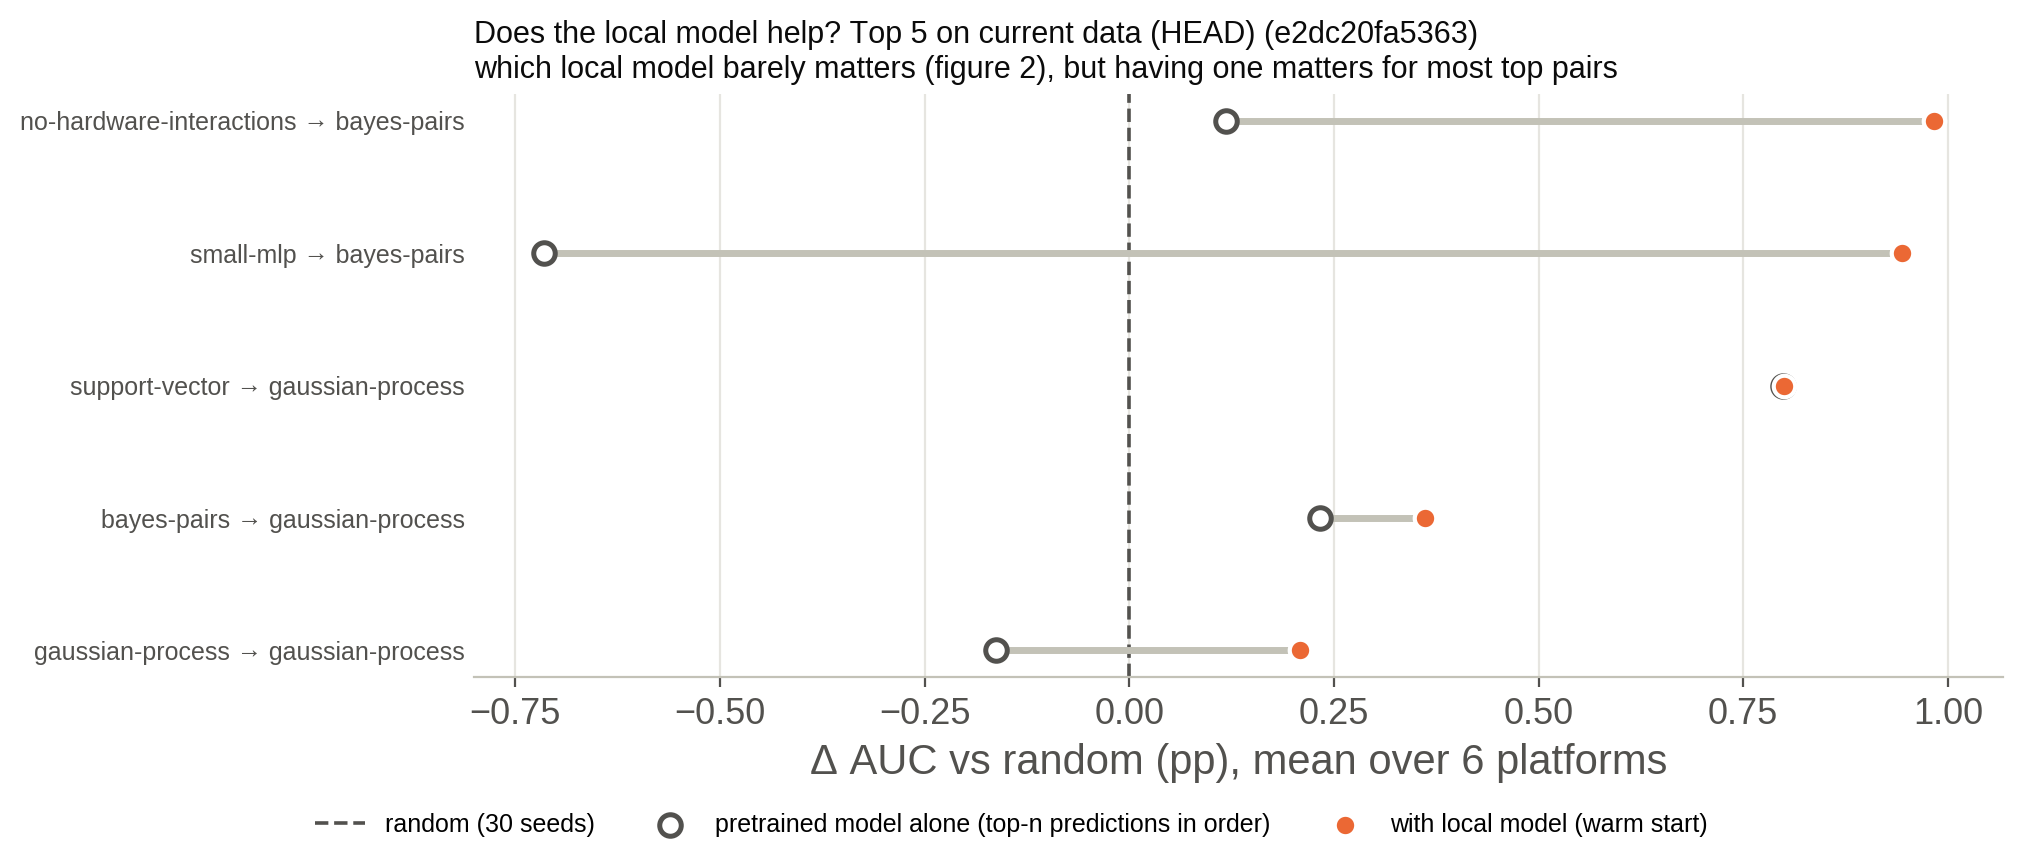

In [18]:
# Figure 8: pretrained model alone vs with a local model (current data)
TOP_HISTORICAL = list(dict.fromkeys(h for h, _ in TOP))
tag = ",".join(sorted(TOP_HISTORICAL)) + "|" + ",".join(VARYING)
pretrained_alone = ms.with_auc(ms.cached(
    CACHE / f"pretrained-only-{current_data}-{HIST_SEEDS}-{hashlib.sha1(tag.encode()).hexdigest()[:8]}.csv",
    lambda: ms.pretrained_only(current_table, TOP_HISTORICAL, HIST_SEEDS, JOBS, vary=VARYING), RECOMPUTE))
alone_platform = pretrained_alone.groupby(["historical", "platform"]).auc.mean()
alone = (alone_platform - random_mean["current"].auc.reindex(
    alone_platform.index.get_level_values("platform")).to_numpy()).groupby("historical").mean()
with_local = final[("current", "Δ auc")]

rows = TOP[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
ax.axvline(0, color=INK2, ls="--", lw=1.3, label="random (30 seeds)")
for i, (historical, local) in enumerate(rows):
    a, b = alone[historical], with_local[(historical, local)]
    ax.plot([a, b], [i, i], color=NEUTRAL, lw=2.5, zorder=2)
    ax.scatter(a, i, s=60, facecolor=SURFACE, edgecolor=INK2, linewidth=1.8, zorder=3,
               label="pretrained model alone (top-n predictions in order)" if i == 0 else None)
    ax.scatter(b, i, s=60, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5, zorder=4,
               label="with local model (warm start)" if i == 0 else None)
ax.set_yticks(range(len(rows)), [f"{h} → {l}" for h, l in rows], fontsize=9)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Δ AUC vs random (pp), mean over 6 platforms")
fig.legend(loc="outside lower center", ncol=3, frameon=False, fontsize=9)
ax.set_title(f"Does the local model help? Top 5 on {NAMES['current']} ({current_commit})\n"
             "which local model barely matters (figure 2), but having one matters for most top pairs",
             loc="left", fontsize=11)
plt.show()

## 7. Conclusions

- **Top 5 for live runs:** `no-hardware-interactions → bayes-pairs`, `small-mlp → bayes-pairs`, `support-vector → gaussian-process`, `bayes-pairs → gaussian-process`, `gaussian-process → gaussian-process`. Only the first three lead clearly on both snapshots; #4 and #5 are only marginally above random on the current data. Also run `random` live as a control.
- **Margins are small:** on the current data the top 3 gain about +1 pp AUC over random, mostly from about build 12 onwards. After 25 builds random is within about 1 pp.
- **The ranking is uncertain:** every 95 % bootstrap interval over the 6 platforms includes 0 (figure 7), so the top 3 are not clearly separated. Much of the lead of `no-hardware-interactions → bayes-pairs` and `support-vector → gaussian-process` comes from 8845HS alone (figure 6).
- **Cold start never beats random** on either data snapshot.
- **The historical model decides** (about 83 % of the variance); *which* local model is used explains about 1 %. *Using* one still helps: without a local model most top pairs lose much or all of their lead, only `support-vector` is as good alone (figure 8). Use bayes-pairs or GP as the local model.
- **small-mlp is unreliable.** Its ZIP rank 1 came from a lucky seed, and even with a fixed seed it is not reproducible between runs. Expect high variance in live runs.
- **Results depend on the data.** With the current data most pairs lose about 5 pp on the 5800X.

## 8. Random baseline by seed and hardware

Evaluation ZIP snapshot. Figure 9 averages each seed across hardware. Figure 10 averages each hardware platform across seeds. The dashed line in both figures is the overall mean.

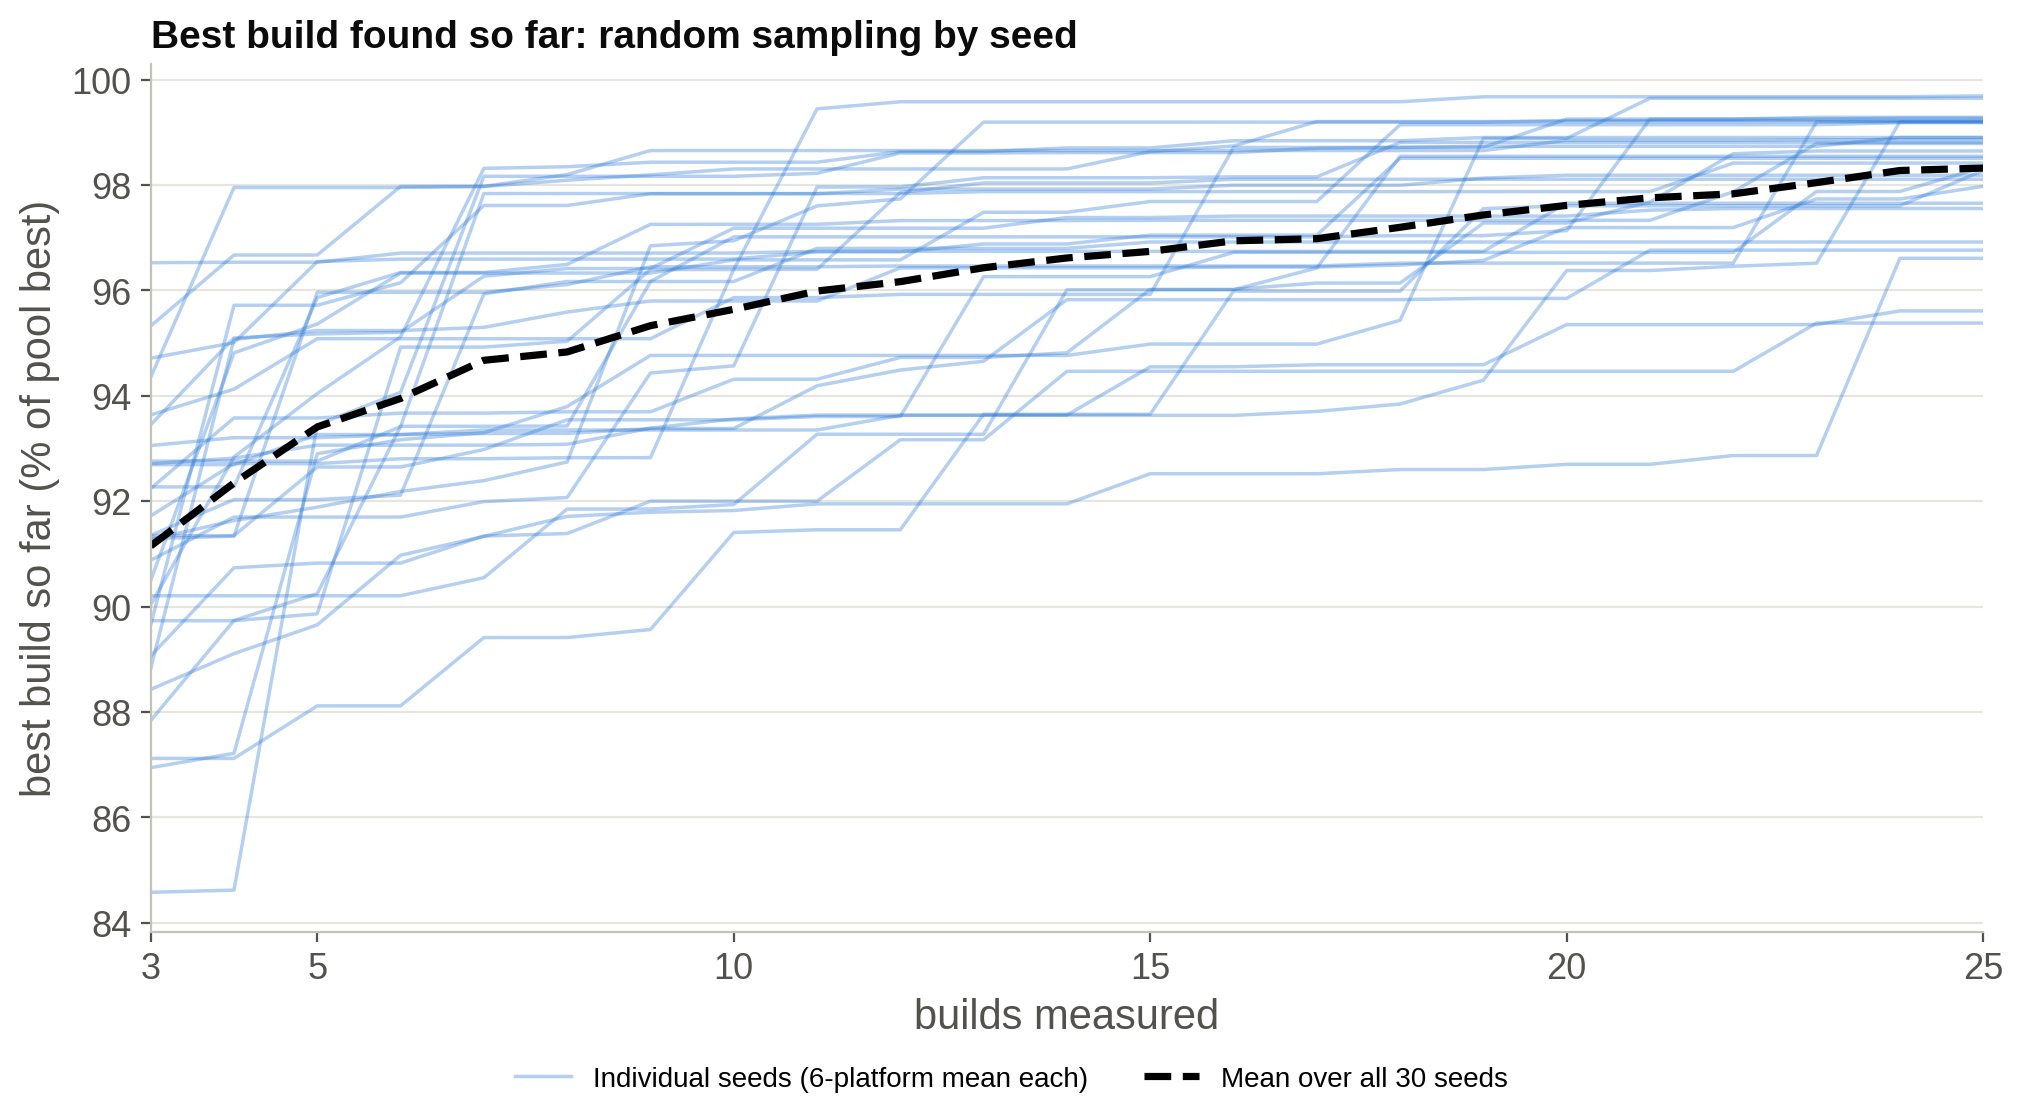

In [19]:
# Figure 9: best build found so far for each random seed
seed_traces = random["eval"].groupby("seed")[ms.BEST].mean()
mean_trace = seed_traces.mean()
platform_count = random["eval"]["platform"].nunique()

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for i, trace in enumerate(seed_traces.to_numpy()):
    ax.plot(ms.STEPS, trace, color=SERIES[0], alpha=0.35, lw=1.25,
            label=f"Individual seeds ({platform_count}-platform mean each)" if i == 0 else None)
ax.plot(ms.STEPS, mean_trace, color="black", ls="--", lw=2.6,
        label=f"Mean over all {len(seed_traces)} seeds")

ax.set_title("Best build found so far: random sampling by seed",
             loc="left", fontsize=14, weight="bold")
ax.set(xlabel="builds measured", ylabel="best build so far (% of pool best)",
       xlim=(ms.STEPS[0], ms.STEPS[-1]), ylim=(None, 100.3),
       xticks=[3, 5, 10, 15, 20, 25])
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
fig.legend(loc="outside lower center", ncol=2, frameon=False, fontsize=10)
plt.show()

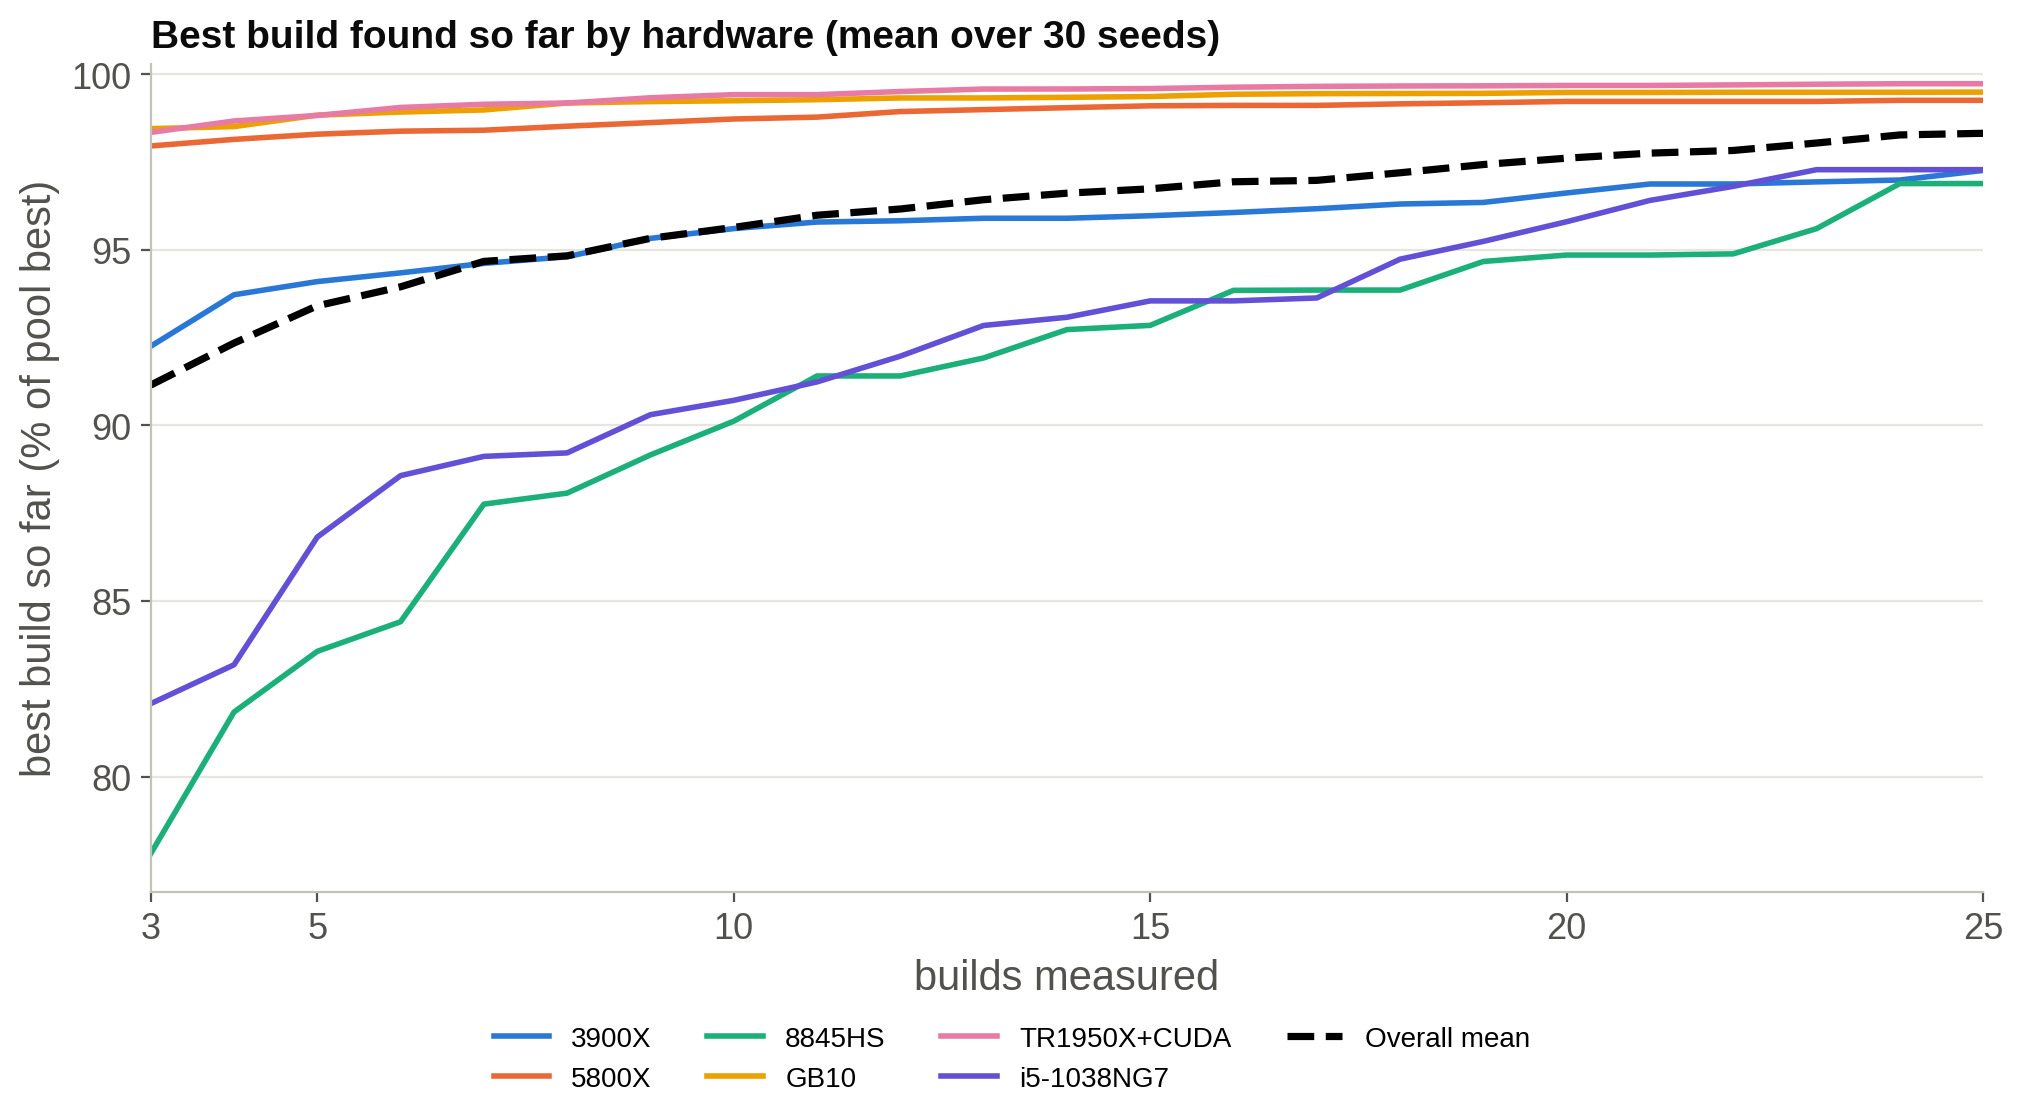

In [20]:
# Figure 10: best build found so far by hardware platform
platform_traces = random["eval"].groupby("platform")[ms.BEST].mean()
mean_platform_trace = platform_traces.mean()

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for (platform, trace), color in zip(platform_traces.iterrows(), SERIES):
    ax.plot(ms.STEPS, trace, color=color, lw=2, label=platform)
ax.plot(ms.STEPS, mean_platform_trace, color="black", ls="--", lw=2.6,
        label="Overall mean")

seed_count = random["eval"]["seed"].nunique()
ax.set_title(f"Best build found so far by hardware (mean over {seed_count} seeds)",
             loc="left", fontsize=14, weight="bold")
ax.set(xlabel="builds measured", ylabel="best build so far (% of pool best)",
       xlim=(ms.STEPS[0], ms.STEPS[-1]), ylim=(None, 100.3),
       xticks=[3, 5, 10, 15, 20, 25])
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
fig.legend(loc="outside lower center", ncol=4, frameon=False, fontsize=10)
plt.show()

### Measured build performance by hardware

The histograms use the same evaluation snapshot as the random curves above. Each build contributes once, with repeated measurements of that build averaged by the notebook loader. The dotted and dashed lines mark the mean and median runtimes, respectively, converted to percentages of best performance.

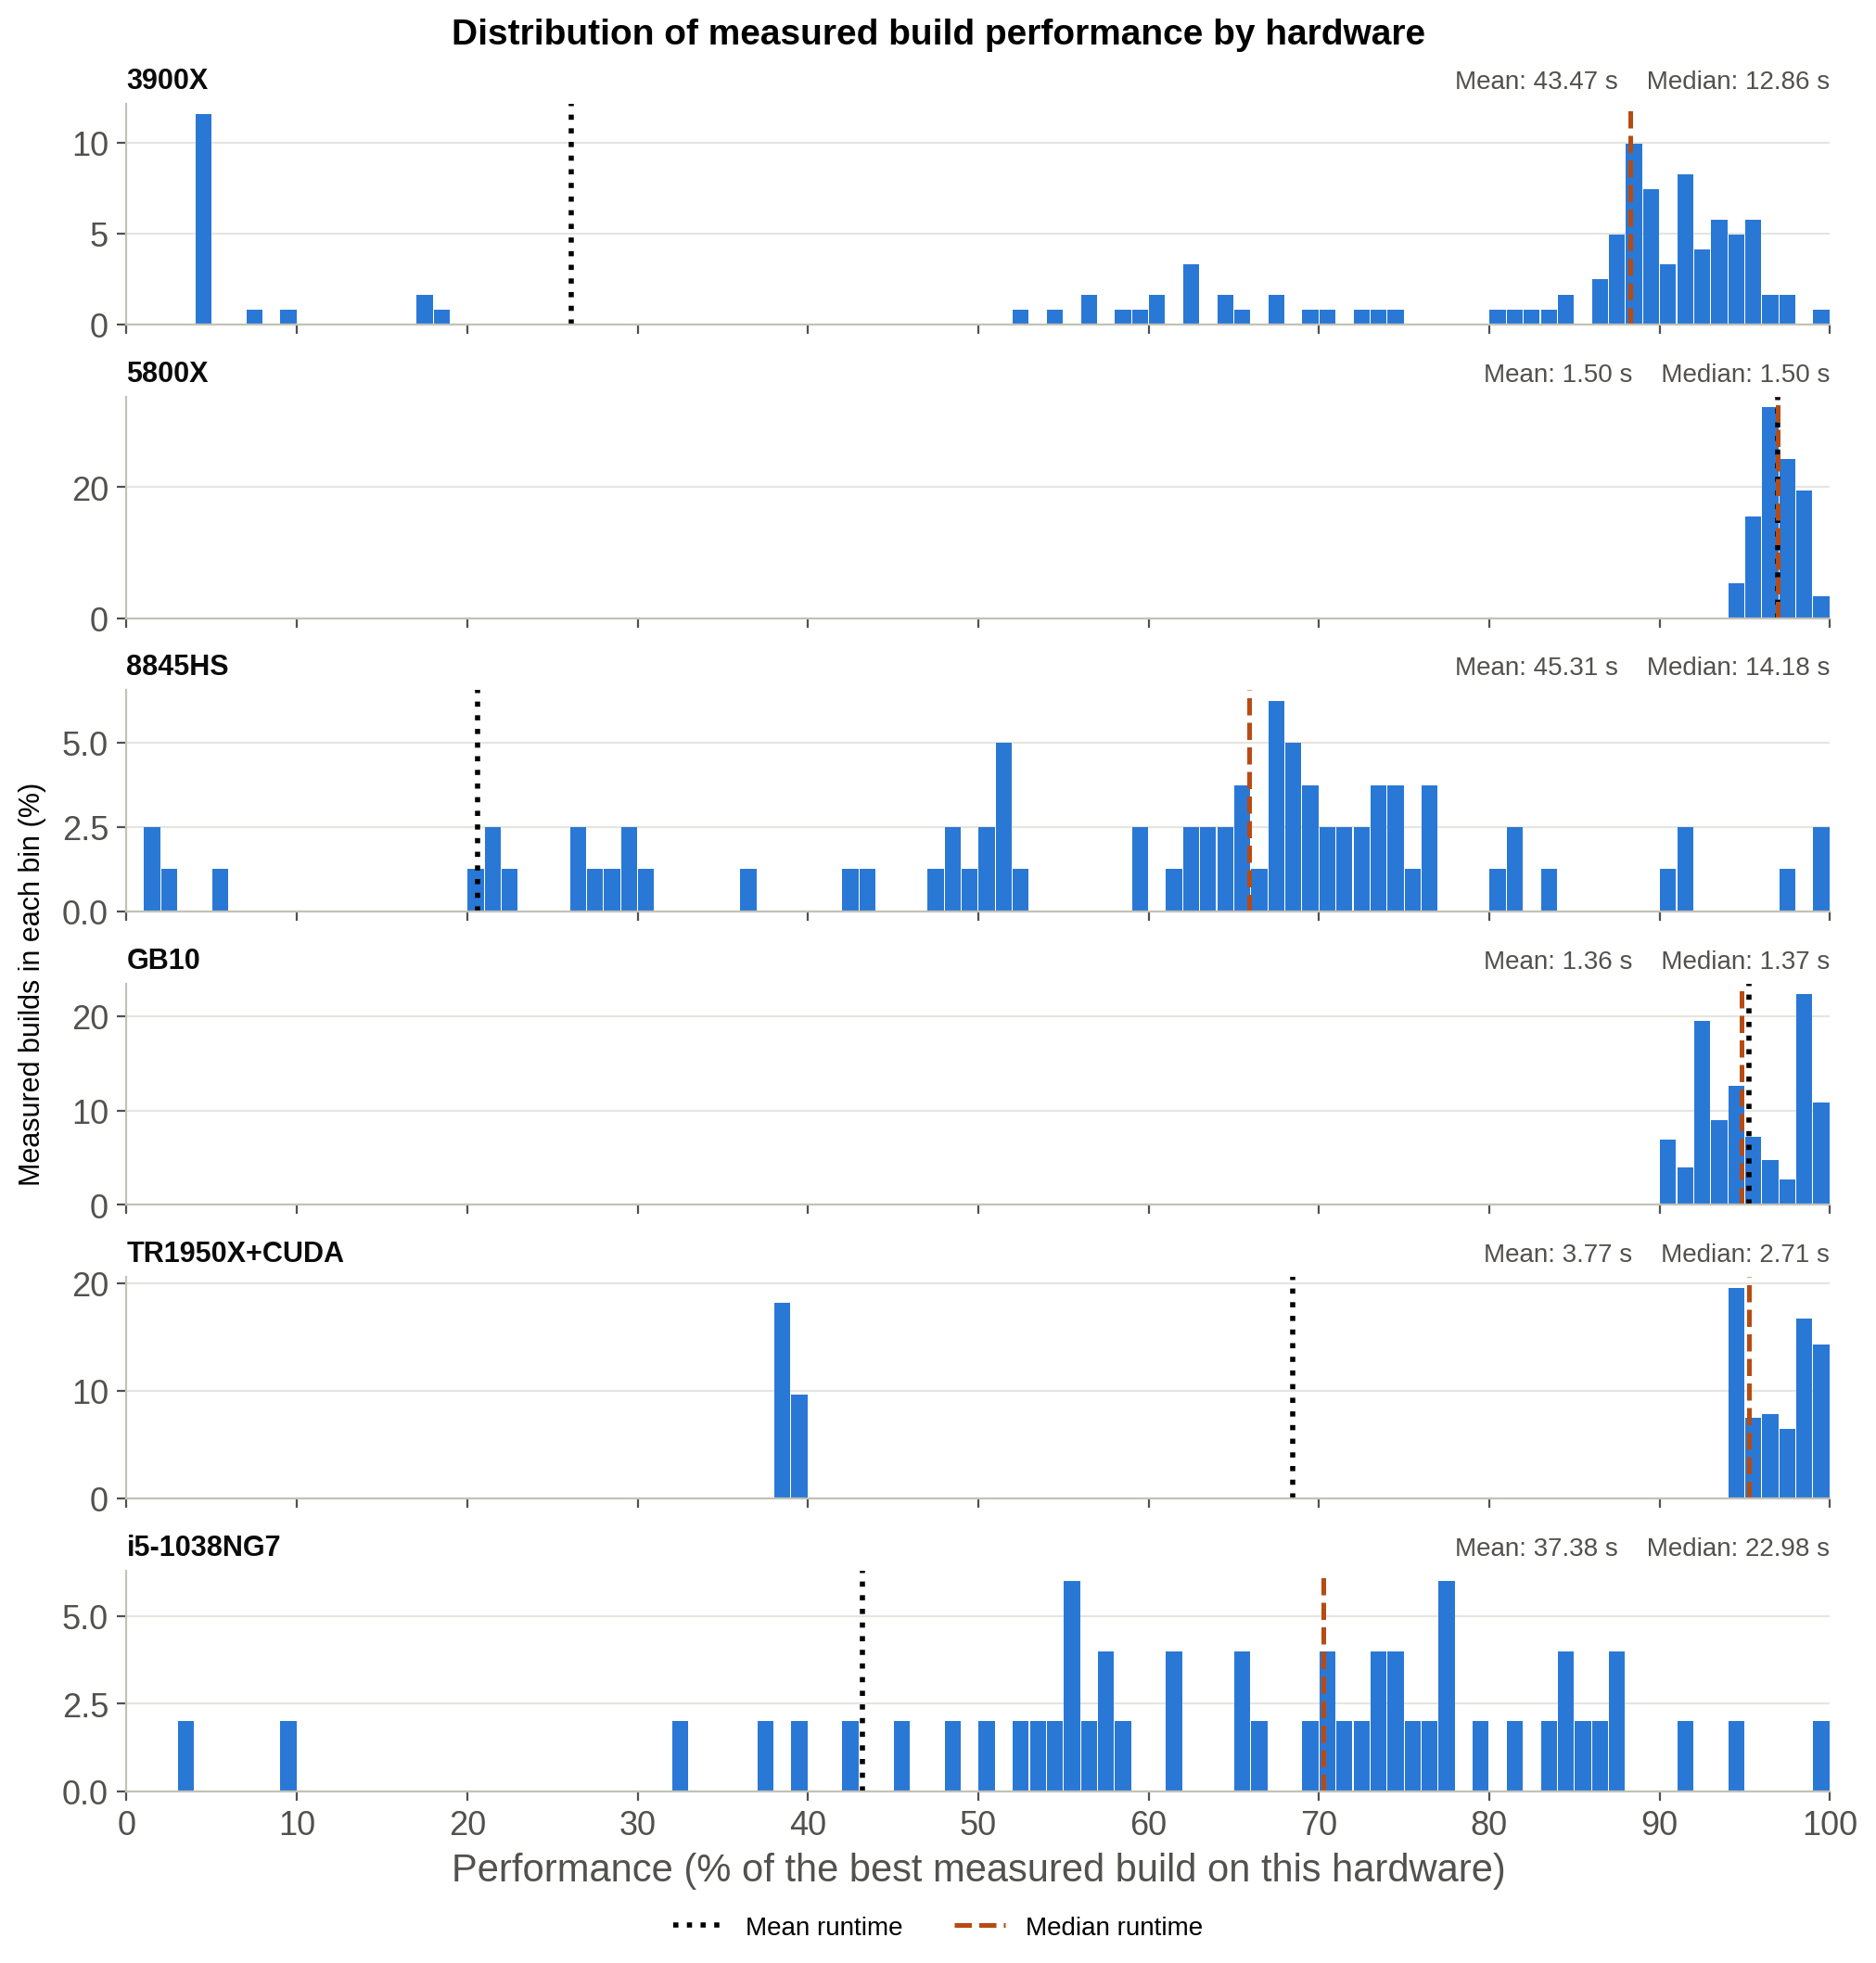

In [21]:
# Figure 11: measured build performance by hardware platform
pool_percent = eval_table.assign(
    hardware=eval_table["platform"].map(lambda platform: ms.SHORT.get(platform, platform)),
    percent_of_best=100 * eval_table["relative"],
)
# The fixed pp512/tg128 workload reports throughput in tokens per second.
pool_percent["runtime_seconds"] = (512 + 128) / pool_percent["performance"]
runtime_by_hardware = pool_percent.groupby("hardware")["runtime_seconds"]
mean_runtime = runtime_by_hardware.mean()
median_runtime = runtime_by_hardware.median()
fastest_runtime = runtime_by_hardware.min()
mean_runtime_percent = 100 * fastest_runtime / mean_runtime
median_runtime_percent = 100 * fastest_runtime / median_runtime
bins = np.arange(0, 101)
fig, axes = plt.subplots(len(mean_runtime_percent), 1, figsize=(10, 10.5),
                         sharex=True, layout="constrained")
for ax, (hardware, mean_percent) in zip(axes, mean_runtime_percent.items()):
    measurements = pool_percent.loc[pool_percent.hardware == hardware, "percent_of_best"].to_numpy()
    weights = np.full(len(measurements), 100 / len(measurements))
    ax.hist(measurements, bins=bins, weights=weights, color=SERIES[0], rwidth=0.94)
    ax.axvline(mean_percent, color="black", ls=":", lw=2)
    ax.axvline(median_runtime_percent[hardware], color="#b74b13", ls="--", lw=1.8)
    ax.set_title(hardware, loc="left", fontsize=11, weight="bold")
    ax.set_title(f"Mean: {mean_runtime[hardware]:.2f} s    Median: {median_runtime[hardware]:.2f} s",
                 loc="right", fontsize=10, color=INK2)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)

left = 10 * np.floor(pool_percent["percent_of_best"].min() / 10)
axes[-1].set(xlim=(left, 100), xticks=np.arange(left, 101, 10),
             xlabel="Performance (% of the best measured build on this hardware)")
fig.supylabel("Measured builds in each bin (%)", fontsize=11)
fig.suptitle("Distribution of measured build performance by hardware",
             fontsize=14, weight="bold")
fig.legend(axes[0].lines, ["Mean runtime", "Median runtime"],
           loc="outside lower center", ncol=2, frameon=False, fontsize=10)
plt.show()

### Chance of finding a near-best build in 25 random picks

The table answers two questions for each hardware platform. What is the chance that at least one of 25 random picks reaches 98% or more of measured peak performance? What is the chance that at least one reaches 96% or more? Peak performance is the best measured build on that platform.

For each hardware platform and threshold, let $N$ be the number of measured build combinations, $K$ the number that qualify, and $n=\min(25,N)$ the number sampled without replacement. The probability of finding at least one qualifying build is

$$
P(\text{at least one hit}) = 1 - \frac{\binom{N-K}{n}}{\binom{N}{n}}.
$$

The fraction is zero if there are fewer than $n$ nonqualifying builds. The platform average weights every hardware platform equally. Percentages that would round up to 100% are rounded down unless a hit is guaranteed.

In [22]:
from scipy.stats import hypergeom

def format_hit_chance(chance, decimals):
    rounded = round(chance, decimals)
    if chance < 100 and rounded == 100:
        rounded = 100 - 10 ** (-decimals)
    return f"{rounded:.{decimals}f}%"

thresholds = [98, 96]
pools_by_hardware = pool_percent.groupby("hardware")["percent_of_best"]
pool_sizes = pools_by_hardware.size()
sample_sizes = pool_sizes.clip(upper=25)
hit_chances = pd.DataFrame(index=pool_sizes.index)
for threshold in thresholds:
    qualifying = pool_percent["percent_of_best"].ge(threshold).groupby(pool_percent["hardware"]).sum()
    chance = 100 * hypergeom.sf(0, pool_sizes, qualifying, sample_sizes)
    guaranteed = pool_sizes - qualifying < sample_sizes
    hit_chances[threshold] = np.where(guaranteed, 100, np.minimum(chance, np.nextafter(100.0, 0.0)))

chance_table = hit_chances[[98, 96]].rename(columns=lambda threshold: f"≥{threshold}% of best")
chance_table.loc["Platform average"] = chance_table.mean()
display(chance_table.style.format(lambda chance: format_hit_chance(chance, 2)))

,≥98% of best,≥96% of best
hardware,,
3900X,20.66%,69.25%
5800X,99.87%,99.99%
8845HS,53.01%,68.07%
GB10,99.99%,99.99%
TR1950X+CUDA,99.99%,99.99%
i5-1038NG7,50.00%,50.00%
Platform average,70.59%,81.22%


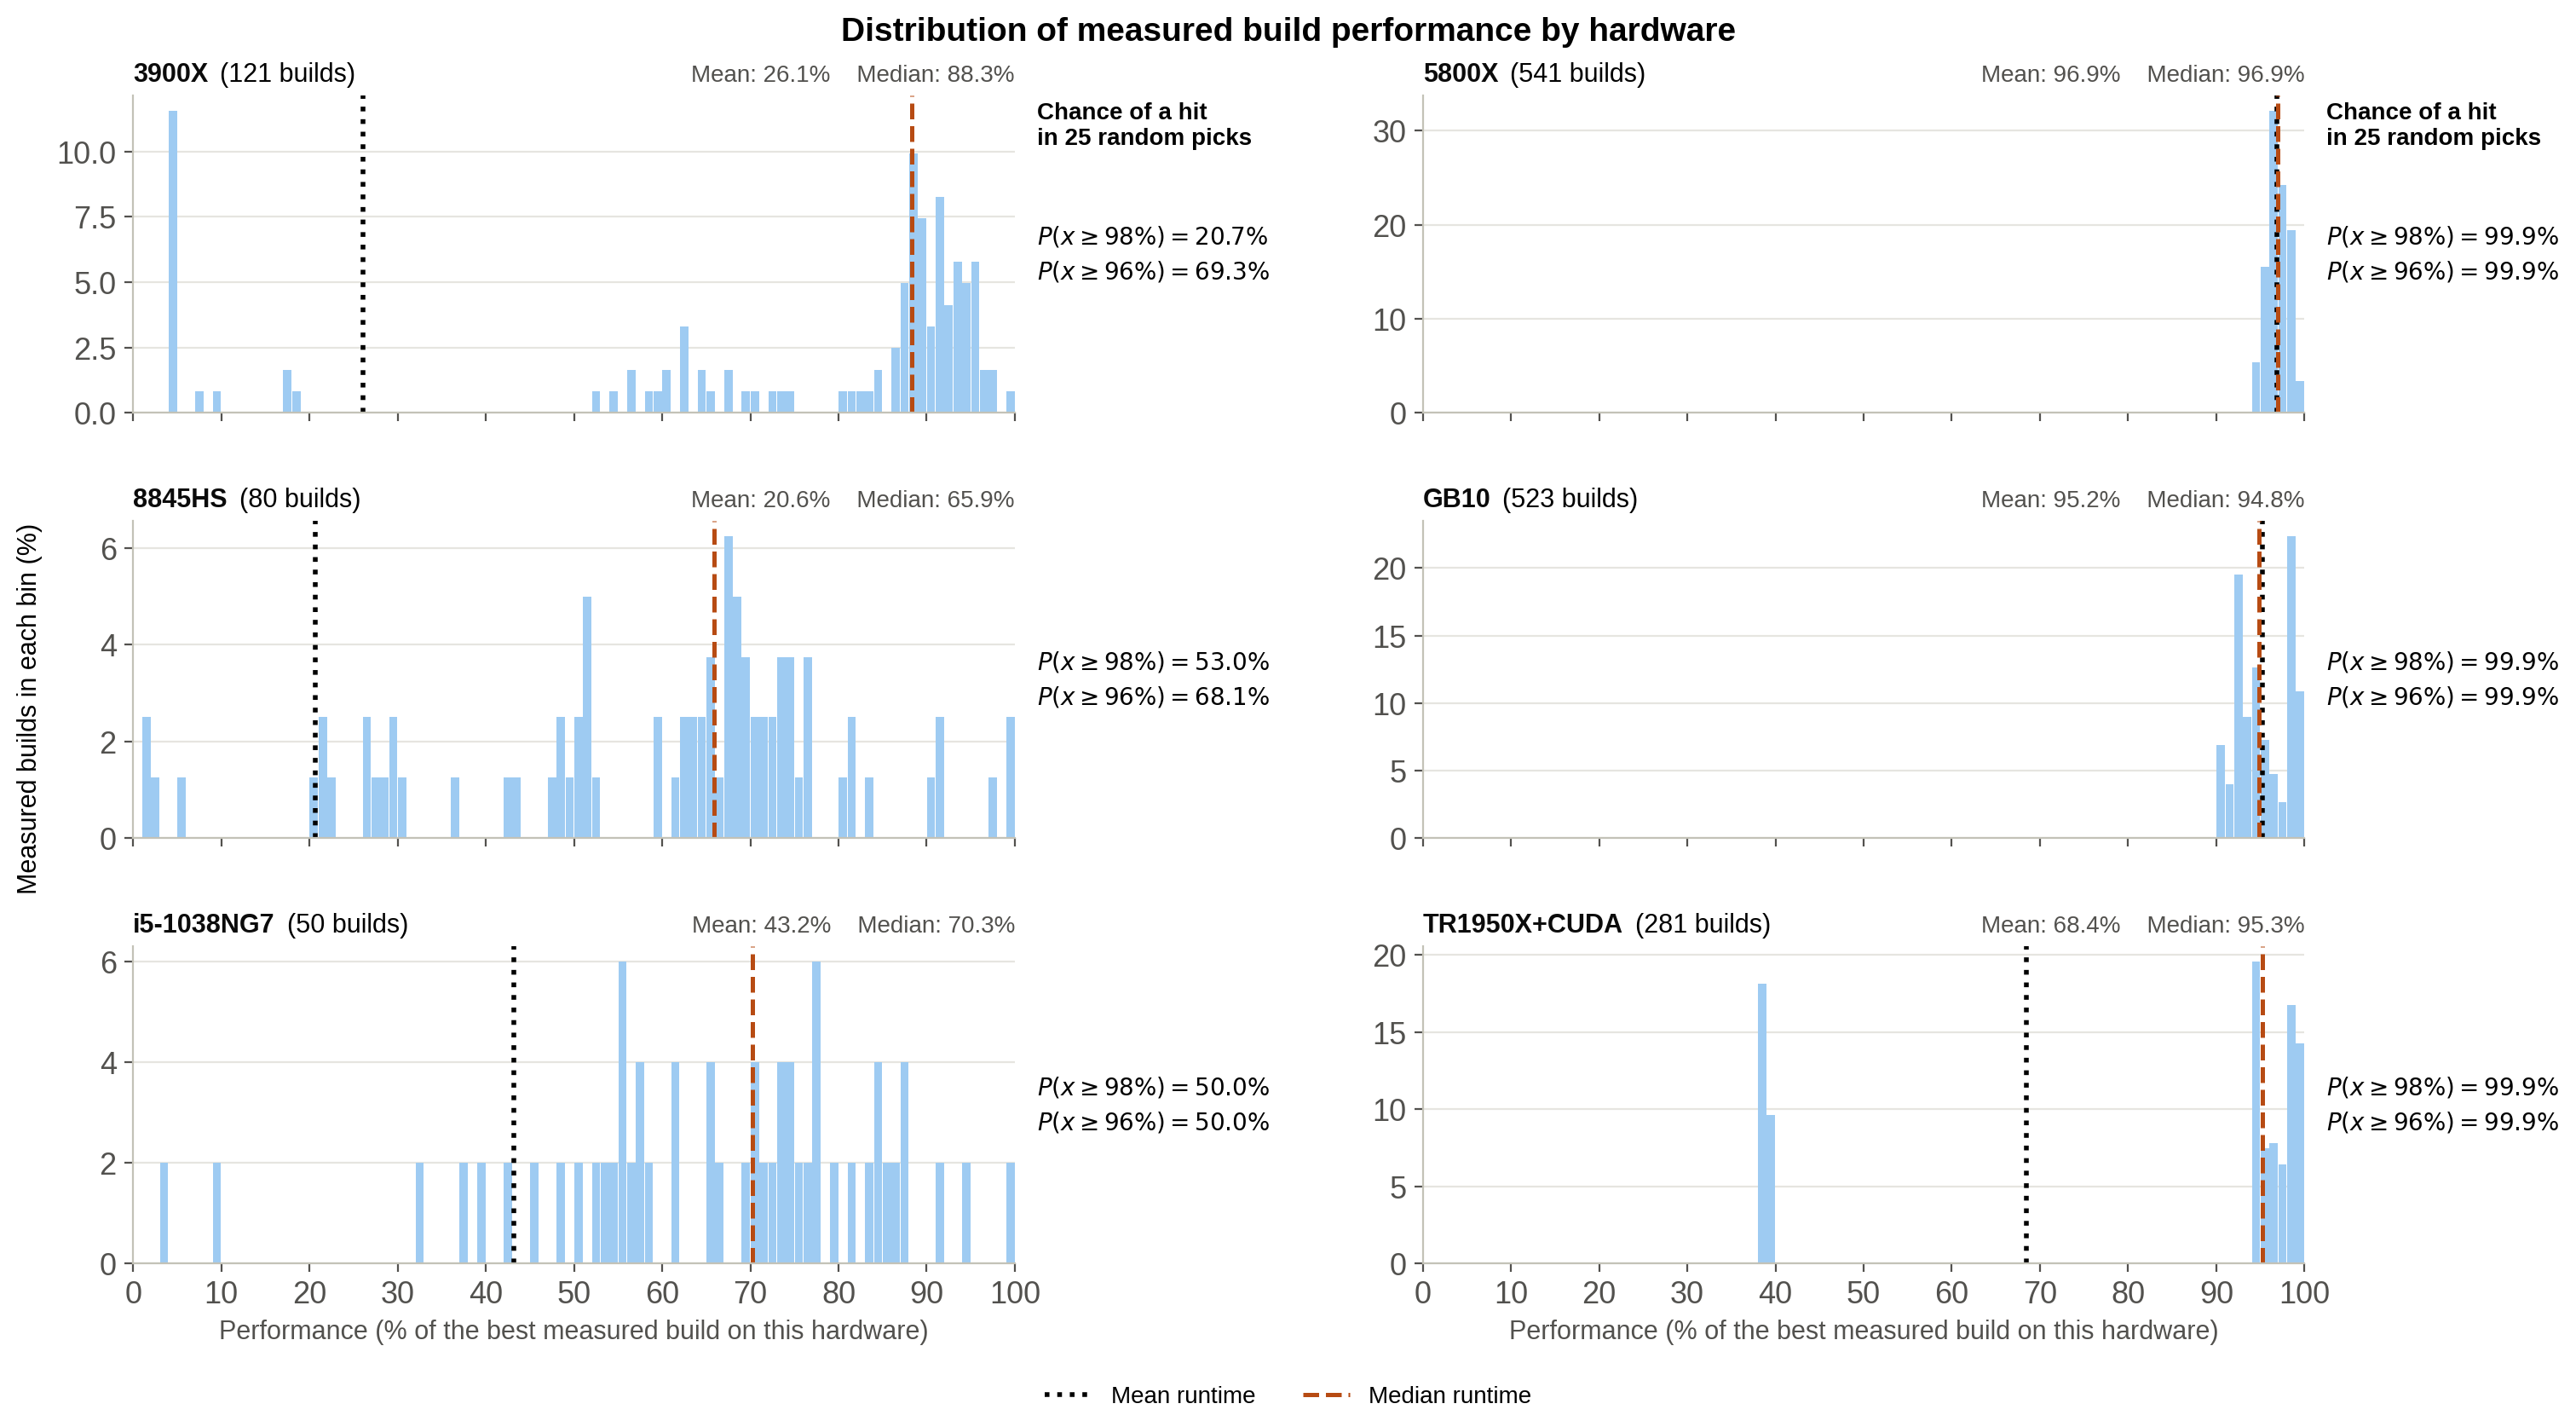

In [23]:
# Figure 12: build performance distributions with random sampling odds
right_platforms = [
    hardware for hardware, chances in hit_chances.iterrows()
    if all(format_hit_chance(chance, 1) == "99.9%" for chance in chances)
]
left_platforms = [hardware for hardware in hit_chances.index if hardware not in right_platforms]
fig, axes = plt.subplots(3, 2, figsize=(15, 8.2), sharex="col", layout="constrained")
fig.get_layout_engine().set(hspace=0.12, wspace=0.08)
for ax, hardware in zip(axes.T.flat, left_platforms + right_platforms):
    mean_percent = mean_runtime_percent[hardware]
    measurements = pools_by_hardware.get_group(hardware).to_numpy()
    weights = np.full(len(measurements), 100 / len(measurements))
    ax.hist(measurements, bins=bins, weights=weights, color="#9ecbf2", rwidth=0.94)
    ax.axvline(mean_percent, color="black", ls=":", lw=2)
    ax.axvline(median_runtime_percent[hardware], color="#b74b13", ls="--", lw=1.8)
    hardware_title = ax.set_title(hardware, loc="left", fontsize=11, weight="bold")
    ax.annotate(f"({pool_sizes[hardware]:,} builds)", xy=(1, 0.5),
                xycoords=hardware_title, xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=11, weight="normal", annotation_clip=False)
    ax.set_title(f"Mean: {mean_percent:.1f}%    Median: {median_runtime_percent[hardware]:.1f}%",
                 loc="right", fontsize=10, color=INK2)
    odds_label = "\n".join(
        fr"$P(x \geq {threshold}\%) = {format_hit_chance(hit_chances.loc[hardware, threshold], 1)[:-1]}\%$"
        for threshold in (98, 96)
    )
    ax.text(1.025, 0.5, odds_label, transform=ax.transAxes,
            va="center", fontsize=10, linespacing=1.5)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)

for column in axes.T:
    column[0].text(1.025, 0.98, "Chance of a hit\nin 25 random picks",
                   transform=column[0].transAxes, va="top", fontsize=10, weight="bold")
    column[-1].set(xlim=(left, 100), xticks=np.arange(left, 101, 10))
    column[-1].set_xlabel("Performance (% of the best measured build on this hardware)", fontsize=11)
fig.supylabel("Measured builds in each bin (%)", fontsize=11)
fig.suptitle("Distribution of measured build performance by hardware",
             fontsize=14, weight="bold")
fig.legend(axes[0, 0].lines, ["Mean runtime", "Median runtime"],
           loc="outside lower center", ncol=2, frameon=False, fontsize=10, borderaxespad=0.15)
plt.show()